# Análises Estratégicas — SIASUS / Ijuí-RS
## T3 · Aulas 2 e 3: limpeza, análises para o gestor municipal e visualização

**Fonte:** VIEW `dbsia.pa_ijui` (produção ambulatorial do SIASUS — arquivo PARS, apenas estabelecimentos de Ijuí, `pa_ufmun = '431020'`) e tabela de granularidade temporal `DIMTEMPO` (gerada pelo script `04-gera-dimtempo-mysql.sql`).

**Roteiro**

| Seção | Pergunta do gestor |
|---|---|
| 1 | Validação da carga e análise exploratória: dimensão, tipos, estatísticas, ausentes e inválidos |
| 2 | Limpeza e preparação: "Não informado" e tratamento de duplicados |
| 3 | Volume e perfil: último mês/bimestre/trimestre, especialidades e evolução temporal |
| 4 | Produção por estabelecimento: ranking e aprovados × produzidos |
| 5 | Perfil demográfico e epidemiológico: sexo, faixa etária e CID |
| 6 | Fluxos regionais: município, Região de Saúde e Macrorregião de origem dos pacientes |
| 7 | Recursos financeiros: aprovado × produzido e gasto médio |
| 8 | Áreas críticas: oncologia, saúde mental e atenção básica |
| 9 | Conclusões e limitações |

**Convenções usadas no notebook**

- **Produzido** = informado pelo estabelecimento (`pa_qtdpro`, `pa_valpro`). **Aprovado** = aceito pelo processamento do SUS (`pa_qtdapr`, `pa_valapr`).
- **Registro** é uma linha do arquivo; **quantidade** é o número de procedimentos daquela linha (um registro pode conter vários procedimentos).
- Cores fixas: **azul = produzido** e **laranja = aprovado** em todos os gráficos.

**Ordem de execução:** executar as células de cima para baixo. As credenciais do MySQL são solicitadas **uma única vez** (Seção 0).

## 0. Preparação do ambiente

### Instalação das bibliotecas (executar uma vez, se necessário)

```python
%pip install pandas numpy mysql-connector-python matplotlib seaborn
```

In [1]:
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Estilo visual: fundo claro, grade discreta, sem bordas superiores/direitas.
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Cores fixas por significado (a mesma medida tem sempre a mesma cor).
COR_PRODUZIDO = "#2a78d6"   # azul    -> produzido (apresentado)
COR_APROVADO = "#eb6834"    # laranja -> aprovado
COR_SERIE = "#1c5cab"       # azul escuro -> gráficos de uma única série
COR_NEUTRA = "#898781"      # cinza   -> "Não informado"
COR_FEMININO = "#6250d6"    # violeta
COR_MASCULINO = "#1baf7a"   # verde-água
CORES_CATEGORIAS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                    "#e87ba4", "#008300", "#6250d6", "#e34948"]

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

### Funções auxiliares

Funções reutilizadas em várias análises: normalização de texto (remove acentos, para comparar descrições e buscar termos), formatação no padrão brasileiro e um resumo padrão de produção (registros, quantidades e valores produzidos/aprovados).

In [2]:
def normalizar(serie):
    """Remove acentos, converte para maiúsculas e retira espaços extras."""
    return (serie.astype(str)
                 .map(lambda s: unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode("ascii"))
                 .str.upper()
                 .str.strip())


def br_num(x, casas=0):
    """Formata número no padrão brasileiro: 1.234.567,89"""
    return f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def br_moeda(x):
    return "R$ " + br_num(x, 2)


def br_pct(x, casas=1):
    """Percentual no padrão brasileiro: 12,5%"""
    return br_num(x, casas) + "%"


def formatar_eixo(ax, eixo="y"):
    """Separador de milhar no padrão brasileiro no eixo informado."""
    formato = mticker.FuncFormatter(lambda v, _: br_num(v))
    (ax.yaxis if eixo == "y" else ax.xaxis).set_major_formatter(formato)


def rotulo_curto(texto, n=45):
    texto = str(texto)
    return texto if len(texto) <= n else texto[: n - 1] + "…"


def resumo_producao(df, por):
    """Agrega registros, quantidades e valores (produzidos e aprovados) pelas colunas em `por`."""
    r = (df.groupby(por, dropna=False, observed=True, as_index=False)
           .agg(Registros=("Procedimento", "size"),
                QtdProduzida=("pa_qtdpro", "sum"),
                QtdAprovada=("pa_qtdapr", "sum"),
                ValorProduzido=("pa_valpro", "sum"),
                ValorAprovado=("pa_valapr", "sum")))
    r["TaxaAprovQtd_%"] = (r["QtdAprovada"] / r["QtdProduzida"].where(r["QtdProduzida"] > 0) * 100).round(1)
    r["TaxaAprovValor_%"] = (r["ValorAprovado"] / r["ValorProduzido"].where(r["ValorProduzido"] > 0) * 100).round(1)
    return r


def barras_produzido_aprovado(df, rotulo, ax, medida="Qtd", titulo=""):
    """Barras horizontais lado a lado: produzido (azul) x aprovado (laranja)."""
    colunas = ["QtdProduzida", "QtdAprovada"] if medida == "Qtd" else ["ValorProduzido", "ValorAprovado"]
    dados = df.set_index(df[rotulo].map(rotulo_curto))[colunas].iloc[::-1]
    dados.columns = ["Produzido", "Aprovado"]
    dados.plot(kind="barh", ax=ax, color=[COR_PRODUZIDO, COR_APROVADO], width=0.75)
    ax.set_title(titulo)
    ax.set_ylabel("")
    ax.set_xlabel("Quantidade de procedimentos" if medida == "Qtd" else "Valor (R$)")
    formatar_eixo(ax, "x")
    ax.legend(title=None, loc="lower right")

### Conexão com o MySQL

Mesma função de conexão utilizada nas aulas anteriores. As credenciais são solicitadas ao executar a carga dos dados.

In [3]:
# conexao.py
from getpass import getpass
from mysql.connector import connect, Error

def usar_conexao(acao):
    try:
        with connect(
            host="localhost",               # Endereço do servidor MySQL (localhost)
            user=input("Usuário: "),        # Solicita ao usuário o nome de login
            password=getpass("Senha: ")     # Solicita a senha de forma oculta
        ) as connection:
            print("Conexão estabelecida:", connection)
            return acao(connection)
    except Error as e:
        print("Ocorreu um erro ao conectar com o BD: ", e)

### Carga dos dados: VIEW `pa_ijui` + tabela `DIMTEMPO`

Em **uma única conexão**:

1. Verifica se a tabela `DIMTEMPO` existe no schema `dbsia`. Se **não existir** (ou se `RECRIAR_DIMTEMPO = True`), executa o script **`04-gera-dimtempo-mysql.sql`** (que deve estar na mesma pasta deste notebook). O script gera um registro por mês, de jan/2010 até o mês corrente, com os atributos de mês, bimestre (`anobi`, ex.: `2026B4`), trimestre (`anotri`, ex.: `2026T3`) e semestre.
2. Carrega a VIEW `dbsia.pa_ijui` no DataFrame `tabela`.
3. Carrega a `DIMTEMPO` no DataFrame `dimtempo`.
4. Verifica se a VIEW `pa_ijui` já tem as colunas usadas nas análises. Se faltar alguma, executa o script **`view.sql`** (mesma pasta), que recria a VIEW:

   | Coluna | Origem no PARS | Uso |
   |---|---|---|
   | `CodProcedimento` | `pa_proc_id` | Área pela hierarquia oficial SIGTAP (Seção 3.3) |
   | `TipoUnidade` | `pa_tpups` | Tipo de estabelecimento do CNES (Seção 4) |
   | `Instrumento` | `pa_docorig` | BPA, APAC ou RAAS: explica ausentes e duplicados (Seções 1 e 2) |
   | `NumAutorizacao` | `pa_autoriz` | Número da APAC: estima pacientes em oncologia (Seção 8.1) |
   | `Competencia` | `pa_cmp` | Mês do atendimento × mês de processamento (Seção 3.4) |
   | `UFPaciente`, `RegiaoSaudePaciente`, `MacrorregiaoPaciente` | `pa_munpcn` → `tb_municip`, `rl_municip_regsaud`/`tb_regsaud`, `rl_municip_macsaud`/`tb_macsaud` | Fluxos por Região e Macrorregião de Saúde (Seção 6.2) |
   | `CodMunicipioPaciente`, `LatPaciente`, `LonPaciente` | `pa_munpcn`, `tb_municip.nu_latitud`/`nu_longit` | Mapa dos fluxos de pacientes (Seção 6.3) |

   Antes da VIEW, se as tabelas de relação município → região não existirem, executa **`06-carga-regioes.sql`**.

5. Coleta os números da **validação da carga** (Seção 1.0) e a lista de UBS/ESF cadastradas em Ijuí no CNES (Seção 8.3).

A ordem importa: a DIMTEMPO é criada antes da VIEW, porque a VIEW depende dela.

O script SQL é lido pelo Python, os comentários (`--`) são removidos e cada comando separado por `;` é executado em sequência.

In [4]:
ARQUIVO_DIMTEMPO = Path("04-gera-dimtempo-mysql.sql")
ARQUIVO_REGIOES = Path("06-carga-regioes.sql")
ARQUIVO_VIEW = Path("view.sql")
RECRIAR_DIMTEMPO = False   # True força a recriação da DIMTEMPO (o script faz DROP TABLE IF EXISTS)
RECRIAR_VIEW = False       # True força a recriação da VIEW pa_ijui a partir de view.sql
COLUNAS_VIEW = ["CodProcedimento", "TipoUnidade", "Instrumento", "NumAutorizacao", "Competencia",
                "UFPaciente", "RegiaoSaudePaciente", "MacrorregiaoPaciente",
                "CodMunicipioPaciente", "LatPaciente", "LonPaciente"]
TABELAS_REGIOES = ["rl_municip_regsaud", "rl_municip_macsaud", "tb_macsaud"]


def executar_script_sql(cursor, caminho):
    """Executa um arquivo .sql comando a comando (separados por ';')."""
    script = caminho.read_text(encoding="utf-8")
    script = re.sub(r"--[^\n]*", "", script)              # remove comentários de linha
    comandos = [c.strip() for c in script.split(";") if c.strip()]
    for comando in comandos:
        cursor.execute(comando)
        if cursor.with_rows:                              # ex.: SELECT de conferência no final do script
            linhas = cursor.fetchall()
            print("  Conferência:", linhas[0] if len(linhas) == 1 else f"{len(linhas)} linha(s)")


def carregar_dados(connection):
    with connection.cursor() as cursor:
        cursor.execute("USE dbsia")

        cursor.execute("""
            SELECT COUNT(*) FROM information_schema.tables
            WHERE table_schema = 'dbsia' AND LOWER(table_name) = 'dimtempo'
        """)
        existe = cursor.fetchone()[0] > 0

        if RECRIAR_DIMTEMPO or not existe:
            print("Criando a tabela DIMTEMPO a partir de", ARQUIVO_DIMTEMPO)
            executar_script_sql(cursor, ARQUIVO_DIMTEMPO)
            connection.commit()
        else:
            print("Tabela DIMTEMPO já existe no banco: reutilizando.")

        cursor.execute("""
            SELECT LOWER(table_name) FROM information_schema.tables WHERE table_schema = 'dbsia'
        """)
        tabelas_existentes = {linha[0] for linha in cursor.fetchall()}
        if not set(TABELAS_REGIOES) <= tabelas_existentes:
            print("Carregando regiões e macrorregiões de saúde a partir de", ARQUIVO_REGIOES)
            executar_script_sql(cursor, ARQUIVO_REGIOES)
            connection.commit()
        else:
            print("Tabelas de regiões de saúde já existem no banco: reutilizando.")

        cursor.execute("""
            SELECT LOWER(column_name) FROM information_schema.columns
            WHERE table_schema = 'dbsia' AND LOWER(table_name) = 'pa_ijui'
        """)
        colunas_existentes = {linha[0] for linha in cursor.fetchall()}
        faltando = {c.lower() for c in COLUNAS_VIEW} - colunas_existentes

        if RECRIAR_VIEW or faltando:
            print("Recriando a VIEW pa_ijui a partir de", ARQUIVO_VIEW, "| colunas faltando:", faltando or "-")
            executar_script_sql(cursor, ARQUIVO_VIEW)
        else:
            print("VIEW pa_ijui já contém todas as colunas necessárias: reutilizando.")

        cursor.execute("SELECT * FROM dbsia.pa_ijui")
        tabela = pd.DataFrame(cursor.fetchall(), columns=cursor.column_names)

        cursor.execute("SELECT * FROM dbsia.DIMTEMPO ORDER BY di")
        dimtempo = pd.DataFrame(cursor.fetchall(), columns=cursor.column_names)

        # ---- Validação da carga ----
        # 1) Registros de Ijuí na tabela pars (a VIEW deve devolver exatamente o mesmo número).
        cursor.execute("SELECT COUNT(*) FROM dbsia.pars WHERE pa_ufmun = '431020'")
        registros_pars = cursor.fetchone()[0]
        # 2) Chaves repetidas nas tabelas usadas nos JOINs (cada repetição multiplica linhas na VIEW).
        #    COUNT(DISTINCT) usa a mesma collation do JOIN: 'J450' e 'j450' contam como a mesma chave.
        chaves = {"procedimentos": "ip_cod", "cbo": "cbo", "s_cid": "cd_cod", "cadgerrs": "cnes",
                  "tb_municip": "co_municip", "dimtempo": "anomes",
                  "rl_municip_regsaud": "co_municip", "tb_regsaud": "co_regsaud",
                  "rl_municip_macsaud": "co_municip", "tb_macsaud": "co_macsaud"}
        repetidas = {}
        for tab_aux, chave in chaves.items():
            cursor.execute(f"SELECT COUNT(*) - COUNT(DISTINCT {chave}) FROM dbsia.{tab_aux}")
            repetidas[f"{tab_aux}.{chave}"] = cursor.fetchone()[0]

        # ---- UBS/ESF cadastradas em Ijuí no CNES (para a Seção 8.3) ----
        cursor.execute("""
            SELECT cnes, fantasia FROM dbsia.cadgerrs
            WHERE codufmun = '431020' AND excluido <> '1'
              AND fantasia REGEXP 'UNIDADE BASICA|ESTRATEGIA SAUDE DA FAMILIA|POSTO CENTRAL'
            ORDER BY fantasia
        """)
        ubs_cadastradas = pd.DataFrame(cursor.fetchall(), columns=["CNES", "Estabelecimento"])

        # ---- Municípios do RS com coordenadas e Região de Saúde (fundo do mapa, Seção 6.3) ----
        cursor.execute("""
            SELECT m.co_municip, m.ds_nome, m.nu_latitud, m.nu_longit, r.co_regsaud
            FROM dbsia.tb_municip AS m
            LEFT JOIN dbsia.rl_municip_regsaud AS r ON m.co_municip = r.co_municip
            WHERE m.uf = 'RS'
        """)
        municipios_rs = pd.DataFrame(cursor.fetchall(),
                                     columns=["co_municip", "ds_nome", "nu_latitud", "nu_longit", "co_regsaud"])

    validacao = {"registros_pars": registros_pars, "chaves_repetidas": repetidas}
    return tabela, dimtempo, validacao, ubs_cadastradas, municipios_rs


resultado = usar_conexao(carregar_dados)
if resultado is None:
    raise RuntimeError("Não foi possível carregar os dados. Verifique as credenciais e o banco dbsia.")
tabela, dimtempo, validacao, ubs_cadastradas, municipios_rs = resultado

print(f"VIEW pa_ijui: {len(tabela):,} registros | DIMTEMPO: {len(dimtempo):,} meses")
display(tabela.head())

Conexão estabelecida: <mysql.connector.connection.MySQLConnection object at 0x000001BB967FB8C0>
Tabela DIMTEMPO já existe no banco: reutilizando.
Tabelas de regiões de saúde já existem no banco: reutilizando.
VIEW pa_ijui já contém todas as colunas necessárias: reutilizando.
VIEW pa_ijui: 68,827 registros | DIMTEMPO: 203 meses


,Ano,Mes,AnoBimestre,AnoTrimestre,Competencia,Estabelecimento,TipoUnidade,Instrumento,NumAutorizacao,CodProcedimento,Procedimento,Ocupacao,pa_sexo,pa_idade,pa_cidpri,Diagnostico,MunicipioEstabelecimento,CodMunicipioPaciente,MunicipioPaciente,UFPaciente,LatPaciente,LonPaciente,RegiaoSaudePaciente,MacrorregiaoPaciente,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr
0,2026,7,2026B4,2026T3,202607,HOSPITAL DE CLINICAS IJUI,05,I,0000000000000,0301010072,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico cirurgiao de cabeca e pescoco,M,074,0000,CID NAO INFORMADO,Ijui,230560,Independencia,CE,"-5,39802810026086","-40,3093482605607",5Âª RS Sobral - CE,SOBRAL,1,1,10.00,10.00
1,2026,7,2026B4,2026T3,202607,HOSPITAL DE CLINICAS IJUI,05,I,0000000000000,0301010072,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico urologista,M,070,0000,CID NAO INFORMADO,Ijui,130170,Humaita,AM,"-7,51222495061139","-63,0266980219283",Rio Madeira - AM,LESTE,1,1,10.00,10.00
2,2026,7,2026B4,2026T3,202607,HOSPITAL DE CLINICAS IJUI,05,I,0000000000000,0301010072,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico reumatologista,F,052,0000,CID NAO INFORMADO,Ijui,312230,Divinopolis,MG,"-20,142073974582","-44,8938855338723",DivinÃ³polis - MG,OESTE,1,1,10.00,10.00
3,2026,7,2026B4,2026T3,202607,HOSPITAL DE CLINICAS IJUI,05,I,0000000000000,0301010072,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico reumatologista,F,052,0000,CID NAO INFORMADO,Ijui,312230,Divinopolis,MG,"-20,142073974582","-44,8938855338723",DivinÃ³polis - MG,OESTE,1,1,10.00,10.00
4,2026,7,2026B4,2026T3,202607,HOSPITAL DE CLINICAS IJUI,05,I,0000000000000,0205010024,ECOCARDIOGRAFIA TRANSESOFAGICA,Medico cardiologista,M,075,0000,CID NAO INFORMADO,Ijui,241150,Santo Antonio,RN,"-6,30517392129752","-35,4751369839982",1Âª RegiÃ£o de SaÃºde - SÃ£o JosÃ© de Mipibu - RN,MACRORREGIAO I,1,1,165.00,165.00


---
## 1. Análise exploratória

### 1.0 Validação da carga

**Pergunta:** a VIEW devolve exatamente os registros de Ijuí que estão na tabela `pars`?

Se alguma tabela usada nos `JOIN`s tiver **chave repetida**, cada registro do PARS que usa essa chave volta **duas ou mais vezes**, inflando quantidades e valores. Essas são as **duplicações verdadeiras** da base: criadas na carga, e não no arquivo original.

**Caso encontrado neste trabalho:** o arquivo `S_CID` do DATASUS contém **14 códigos em minúsculo** (`j450`, `m050`, `n63`…, descrição "CID NÃO IDENTIFICADO"). Como a collation do MySQL não diferencia maiúsculas de minúsculas, `J450` = `j450` no `JOIN`, e os registros com esses CIDs (asma, artrite reumatoide, doenças da mama) eram devolvidos em dobro: **+1.550 registros e +R$ 682 mil** de valor aprovado. A correção está no script **`05-corrige-s_cid.sql`**: remove as 14 linhas e cria a `PRIMARY KEY (cd_cod)`, que impede a repetição.

In [5]:
validacao_tabela = pd.DataFrame(
    [("Registros de Ijuí na tabela pars", validacao["registros_pars"]),
     ("Registros devolvidos pela VIEW pa_ijui", len(tabela))]
    + [(f"Chaves repetidas em {chave}", n) for chave, n in validacao["chaves_repetidas"].items()],
    columns=["Verificação", "Resultado"]).set_index("Verificação")
display(validacao_tabela)

if len(tabela) == validacao["registros_pars"] and not any(validacao["chaves_repetidas"].values()):
    print("OK: a VIEW devolve exatamente os registros da pars e nenhuma tabela auxiliar tem chave repetida.")
else:
    print("ATENÇÃO: a VIEW não bate com a pars ou há chaves repetidas. Corrija a tabela auxiliar "
          "(ver 05-corrige-s_cid.sql) antes de interpretar os resultados.")

,Resultado
Verificação,
Registros de Ijuí na tabela pars,68827
Registros devolvidos pela VIEW pa_ijui,68827
Chaves repetidas em procedimentos.ip_cod,0
Chaves repetidas em cbo.cbo,0
Chaves repetidas em s_cid.cd_cod,0
Chaves repetidas em cadgerrs.cnes,0
Chaves repetidas em tb_municip.co_municip,0
Chaves repetidas em dimtempo.anomes,0
Chaves repetidas em rl_municip_regsaud.co_municip,0


OK: a VIEW devolve exatamente os registros da pars e nenhuma tabela auxiliar tem chave repetida.


### 1.1 Dimensão e tipos de variáveis

**Pergunta:** quantas linhas e colunas existem e qual é a natureza de cada variável (numérica, categórica ou textual)?

In [6]:
print("Linhas:", br_num(tabela.shape[0]), "| Colunas:", tabela.shape[1])

# Quantidades e valores chegam do MySQL como texto/Decimal: convertendo para numérico.
colunas_numericas = ["pa_qtdpro", "pa_qtdapr", "pa_valpro", "pa_valapr"]
for coluna in colunas_numericas:
    tabela[coluna] = pd.to_numeric(tabela[coluna])


def natureza(coluna):
    if coluna in colunas_numericas or coluna in ["Ano", "Mes"]:
        return "Numérica"
    if coluna in ["pa_idade", "pa_cidpri", "pa_sexo", "CodProcedimento", "TipoUnidade",
                  "Instrumento", "NumAutorizacao", "Competencia"]:
        return "Código (texto)"
    return "Categórica" if tabela[coluna].nunique() <= 60 else "Textual (descrição)"


tipos = pd.DataFrame({
    "Tipo no pandas": tabela.dtypes.astype(str),
    "Natureza": [natureza(c) for c in tabela.columns],
    "Valores distintos": tabela.nunique(),
    "Exemplo": tabela.iloc[0],
})
display(tipos)

Linhas: 68.827 | Colunas: 28


,Tipo no pandas,Natureza,Valores distintos,Exemplo
Ano,int64,Numérica,1,2026
Mes,int64,Numérica,1,7
AnoBimestre,str,Categórica,1,2026B4
AnoTrimestre,str,Categórica,1,2026T3
Competencia,str,Código (texto),3,202607
Estabelecimento,str,Categórica,18,HOSPITAL DE CLINICAS IJUI
TipoUnidade,str,Código (texto),7,05
Instrumento,str,Código (texto),5,I
NumAutorizacao,str,Código (texto),9384,0000000000000
CodProcedimento,str,Código (texto),813,0301010072


### 1.2 Estatísticas descritivas e distribuições de frequência

`describe()` mostra contagem, média, desvio-padrão, mínimo, quartis e máximo; a **mediana** é acrescentada explicitamente. `value_counts()` gera as distribuições de frequência das variáveis categóricas.

In [7]:
estatisticas = tabela[colunas_numericas].describe().T
estatisticas.insert(2, "mediana", tabela[colunas_numericas].median())
display(estatisticas)

print("Registros por estabelecimento (10 maiores):")
display(tabela["Estabelecimento"].value_counts().head(10).to_frame("Registros"))

print("Códigos de sexo presentes:")
display(tabela["pa_sexo"].value_counts(dropna=False).to_frame("Registros"))

,count,mean,mediana,std,min,25%,50%,75%,max
pa_qtdpro,"68,827.00",6.70,1.00,54.82,0.00,1.00,1.00,1.00,"6,284.00"
pa_qtdapr,"68,827.00",5.30,1.00,49.75,0.00,0.00,1.00,1.00,"5,337.00"
pa_valpro,"68,827.00",91.13,6.30,580.94,0.00,3.37,6.30,17.67,"60,741.37"
pa_valapr,"68,827.00",89.47,3.37,582.18,0.00,0.00,3.37,12.00,"60,741.37"


Registros por estabelecimento (10 maiores):


,Registros
Estabelecimento,
HOSPITAL DE CLINICAS IJUI,24241
HOSPITAL BOM PASTOR IJUI,19158
17 COORDENADORIA REGIONAL DE SAUDE,6051
CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,4326
APAE IJUI,3183
CER III UNIR,2838
CENTRO DE ATENCAO PSICOSSOCIAL CAPS INFANTIL CARAMELO,2825
CENTRO AUDITIVO PROAUDI,2354
CISA,1766


Códigos de sexo presentes:


,Registros
pa_sexo,
F,33636
M,32401
0,2790


**Interpretação:** a média de quantidade por registro é bem maior que a mediana (que é 1). A distribuição é muito assimétrica: a maioria dos registros traz um único procedimento, mas alguns registros consolidados (BPA consolidado) trazem centenas ou milhares. Por isso as análises usam **somas de quantidades**, e não apenas contagem de linhas.

### 1.3 Valores ausentes e valores inválidos

**Pergunta:** onde estão os problemas de qualidade?

No SIASUS, a ausência de informação raramente aparece como `NULL`: ela costuma vir **codificada**. Verificamos:

- **Nulos (`NaN`)** por coluna;
- **Idade** não numérica ou fora da faixa 0–120;
- **Sexo** diferente de `M`/`F`;
- **CID não informado** (`0000` ou vazio);
- **CID inexistente**: código preenchido que não encontrou correspondência na tabela CID-10 (por isso `Diagnostico` ficou nulo no relacionamento da VIEW);
- Inconsistências numéricas: quantidade aprovada maior que a produzida e valores negativos.

Nulos (NaN) por coluna - apenas colunas com ocorrência:


,Nulos
Diagnostico,9
RegiaoSaudePaciente,2790
MacrorregiaoPaciente,2790


,Registros,% do total
CID não informado (0000/vazio),46804,68.00
Sexo diferente de M/F,2790,4.05
Idade não numérica ou fora de 0–120,955,1.39
Valor aprovado > valor produzido,195,0.28
CID inexistente na tabela CID-10,9,0.01
Município do paciente nulo,0,0.00
Qtd aprovada > qtd produzida,0,0.00
Quantidade ou valor negativo,0,0.00


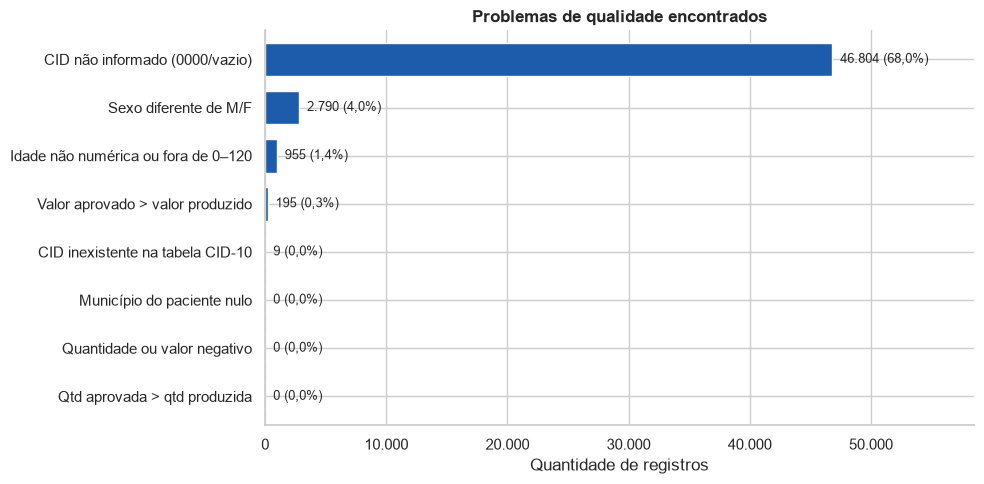

In [8]:
nulos = tabela.isna().sum()
print("Nulos (NaN) por coluna - apenas colunas com ocorrência:")
display(nulos[nulos > 0].to_frame("Nulos"))

idade_num = pd.to_numeric(tabela["pa_idade"], errors="coerce")
cid_bruto = tabela["pa_cidpri"].astype(str).str.strip().str.upper()
cid_vazio = cid_bruto.isin(["", "0000", "NONE", "NAN"])

problemas = pd.Series({
    "Idade não numérica ou fora de 0–120": (~idade_num.between(0, 120)).sum(),
    "Sexo diferente de M/F": (~tabela["pa_sexo"].isin(["M", "F"])).sum(),
    "CID não informado (0000/vazio)": cid_vazio.sum(),
    "CID inexistente na tabela CID-10": (tabela["Diagnostico"].isna() & ~cid_vazio).sum(),
    "Município do paciente nulo": tabela["MunicipioPaciente"].isna().sum(),
    "Qtd aprovada > qtd produzida": (tabela["pa_qtdapr"] > tabela["pa_qtdpro"]).sum(),
    "Valor aprovado > valor produzido": (tabela["pa_valapr"] > tabela["pa_valpro"]).sum(),
    "Quantidade ou valor negativo": (tabela[colunas_numericas] < 0).any(axis=1).sum(),
}).sort_values()

qualidade = problemas.to_frame("Registros")
qualidade["% do total"] = (qualidade["Registros"] / len(tabela) * 100).round(2)
display(qualidade.sort_values("Registros", ascending=False))

ax = qualidade["Registros"].plot(kind="barh", figsize=(10, 5), color=COR_SERIE, width=0.7)
for i, (qtd, pct) in enumerate(zip(qualidade["Registros"], qualidade["% do total"])):
    ax.text(qtd, i, f"  {br_num(qtd)} ({br_pct(pct)})", va="center", fontsize=9)
ax.set_title("Problemas de qualidade encontrados")
ax.set_xlabel("Quantidade de registros")
ax.set_xlim(0, qualidade["Registros"].max() * 1.25 + 1)
formatar_eixo(ax, "x")
plt.tight_layout()
plt.show()

#### Os "inválidos" dependem do instrumento de registro

Cada registro do SIA vem de um **instrumento** (`Instrumento` = `pa_docorig`), e cada um tem regras próprias de preenchimento:

| Código | Instrumento | Identifica o paciente? |
|---|---|---|
| `C` | BPA consolidado | **Não**: só totaliza procedimentos (sem sexo, idade ou CID) |
| `I` | BPA individualizado | Sim |
| `P` / `S` | APAC: procedimento principal / secundário | Sim (alta complexidade: oncologia, medicamentos…) |
| `A` / `B` | RAAS: atenção domiciliar / psicossocial (CAPS) | Sim |

,Registros,% sexo ≠ M/F,% idade inválida,% CID não informado
InstrumentoDesc,,,,
BPA individualizado,46169,0.00,0.00,75.50
APAC principal,8850,0.00,0.00,2.30
RAAS psicossocial,7426,0.00,0.00,100.00
APAC secundário,3592,0.00,0.00,42.10
BPA consolidado,2790,100.00,34.20,100.00


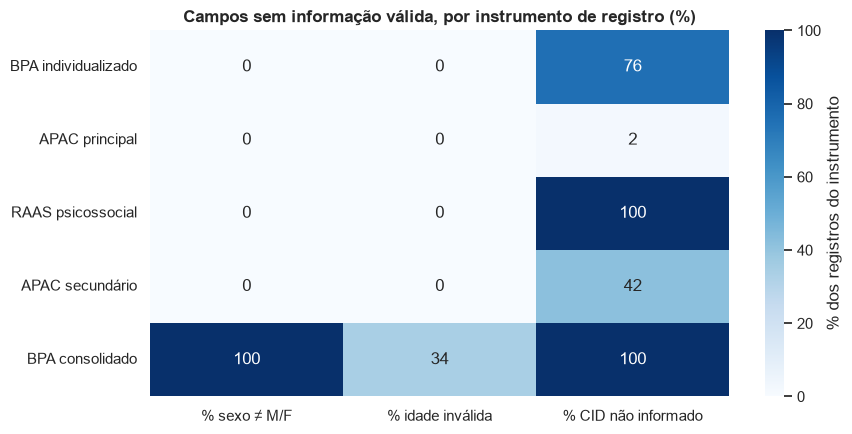

In [9]:
INSTRUMENTOS = {"C": "BPA consolidado", "I": "BPA individualizado", "P": "APAC principal",
                "S": "APAC secundário", "A": "RAAS domiciliar", "B": "RAAS psicossocial"}
tabela["InstrumentoDesc"] = (tabela["Instrumento"].astype(str).str.strip()
                             .map(INSTRUMENTOS).fillna("Outro/ignorado"))

por_instrumento = pd.DataFrame({
    "Registros": tabela["InstrumentoDesc"].value_counts(),
    "% sexo ≠ M/F": (~tabela["pa_sexo"].isin(["M", "F"])).groupby(tabela["InstrumentoDesc"]).mean() * 100,
    "% idade inválida": (~idade_num.between(0, 120)).groupby(tabela["InstrumentoDesc"]).mean() * 100,
    "% CID não informado": cid_vazio.groupby(tabela["InstrumentoDesc"]).mean() * 100,
}).round(1).sort_values("Registros", ascending=False)
display(por_instrumento)

plt.figure(figsize=(9, 4.5))
sns.heatmap(por_instrumento.drop(columns="Registros"), annot=True, fmt=".0f", cmap="Blues",
            vmin=0, vmax=100, cbar_kws={"label": "% dos registros do instrumento"})
plt.title("Campos sem informação válida, por instrumento de registro (%)")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Interpretação:** os "inválidos" **não são erros de digitação**, mas consequência do instrumento. Em jul/2026, **100% dos registros com sexo `0` (2.790) são de BPA consolidado**, que por definição não identifica o paciente. O CID também segue o instrumento: a **APAC principal** traz CID em quase todos os registros (só cerca de 2% sem CID), enquanto o BPA individualizado (cerca de 75% sem CID), o BPA consolidado e a RAAS psicossocial praticamente não o trazem no arquivo. Para a gestão, isso significa que **análises por diagnóstico só são confiáveis para a alta complexidade (APAC)**. A diferença entre quantidade produzida e aprovada também **não é erro de dado**: ela é justamente o que a Seção 4 analisa (glosas e rejeições).

---
## 2. Limpeza e preparação dos dados

### 2.1 Valores nulos → "Não informado"

**Estratégia adotada:** **preencher** com `"Não informado"` em vez de apagar linhas. Apagar removeria procedimentos e valores **reais** (um registro sem CID continua sendo um procedimento pago pelo SUS) e distorceria volumes e valores financeiros.

Além do `NaN`, os códigos que representam ausência (`0000`, `CID NAO INFORMADO`, sexo `0`, idade fora da faixa) também são padronizados. Novas colunas tratadas são criadas e as originais são preservadas:

| Coluna nova | Origem | Regra |
|---|---|---|
| `Sexo` | `pa_sexo` | M → Masculino, F → Feminino, demais → Não informado |
| `Idade` | `pa_idade` | numérica; fora de 0–120 → vazio |
| `FaixaEtaria` | `Idade` | faixas de 10 anos; sem idade válida → Não informado |
| `CID` | `pa_cidpri` | `0000`/vazio/inexistente → Não informado |

In [10]:
tabela_original = tabela.copy()   # cópia para comparação antes x depois

# CID: precisa usar o Diagnostico ORIGINAL (nulo = código inexistente na CID-10).
tabela["CID"] = cid_bruto.where(~cid_vazio & tabela["Diagnostico"].notna(), "Não informado")

# Colunas descritivas: NaN, vazio e marcadores de ausência -> "Não informado".
colunas_descritivas = ["Estabelecimento", "Procedimento", "Ocupacao", "Diagnostico",
                       "MunicipioEstabelecimento", "MunicipioPaciente"]
for coluna in colunas_descritivas:
    tabela[coluna] = (tabela[coluna].fillna("Não informado").astype(str).str.strip()
                      .replace({"": "Não informado", "CID NAO INFORMADO": "Não informado"}))

# Sexo.
tabela["Sexo"] = (tabela["pa_sexo"].astype(str).str.strip()
                  .map({"M": "Masculino", "F": "Feminino"}).fillna("Não informado"))

# Idade e faixa etária.
tabela["Idade"] = pd.to_numeric(tabela["pa_idade"], errors="coerce")
tabela.loc[~tabela["Idade"].between(0, 120), "Idade"] = np.nan
ROTULOS_FAIXA = ["0–9", "10–19", "20–29", "30–39", "40–49", "50–59", "60–69", "70–79", "80+"]
tabela["FaixaEtaria"] = (pd.cut(tabela["Idade"], bins=[-1, 9, 19, 29, 39, 49, 59, 69, 79, 120],
                                labels=ROTULOS_FAIXA)
                         .cat.add_categories("Não informado").fillna("Não informado"))

tratados = pd.DataFrame({
    "Tratados como 'Não informado'": [
        (tabela["Sexo"] == "Não informado").sum(),
        tabela["Idade"].isna().sum(),
        (tabela["CID"] == "Não informado").sum(),
        (tabela["Diagnostico"] == "Não informado").sum(),
        (tabela["MunicipioPaciente"] == "Não informado").sum(),
    ]}, index=["Sexo", "Idade/FaixaEtaria", "CID", "Diagnostico", "MunicipioPaciente"])
display(tratados)
print("Nulos restantes nas colunas tratadas:",
      tabela[colunas_descritivas + ["Sexo", "FaixaEtaria", "CID"]].isna().sum().sum())

,Tratados como 'Não informado'
Sexo,2790
Idade/FaixaEtaria,955
CID,46813
Diagnostico,46813
MunicipioPaciente,0


Nulos restantes nas colunas tratadas: 0


### 2.2 Registros duplicados

São tratados dois tipos de "duplicação":

1. **Duplicação criada na carga** (linhas multiplicadas por `JOIN` com chave repetida). É erro **de verdade**: foi detectada na Seção 1.0 e corrigida **no banco** (`05-corrige-s_cid.sql`). Depois da correção, a VIEW devolve exatamente os registros da `pars`.
2. **Linhas idênticas no próprio arquivo PARS.** O arquivo público do DATASUS **não traz a data do atendimento nem a identificação do paciente** (LGPD). Por isso, atendimentos diferentes no mesmo mês (o mesmo paciente em 4 sessões no CAPS com o mesmo profissional, por exemplo) geram linhas iguais. São **atendimentos legítimos**, pagos pelo SUS e contados nos totais oficiais do DATASUS (TabNet).

**Estratégia adotada:** remover as duplicações do tipo 1 (feito no banco) e **manter** as do tipo 2. A tabela abaixo mostra quanto seria perdido se as linhas idênticas fossem removidas. A opção `REMOVER_LINHAS_IDENTICAS` permite testar esse cenário.

In [11]:
REMOVER_LINHAS_IDENTICAS = False   # True remove as linhas idênticas (NÃO recomendado: são atendimentos reais)

colunas_view = tabela_original.columns.tolist()
duplicados = tabela.duplicated(subset=colunas_view, keep="first")

print(f"Linhas idênticas a outra (cópias excedentes): {br_num(duplicados.sum())} "
      f"({br_pct(duplicados.mean() * 100, 2)} dos registros)")

print("\nInstrumento de registro das linhas idênticas:")
display(tabela.loc[duplicados, "InstrumentoDesc"].value_counts().to_frame("Linhas idênticas"))

print("Exemplo de grupo de linhas idênticas:")
exemplo = tabela[tabela.duplicated(subset=colunas_view, keep=False)]
display(exemplo.sort_values(colunas_view).head(4)[colunas_view])


def totais(df):
    return [len(df), df["pa_qtdpro"].sum(), df["pa_qtdapr"].sum(), df["pa_valpro"].sum(), df["pa_valapr"].sum()]


impacto = pd.DataFrame({"Com todas as linhas": totais(tabela),
                        "Se removesse as idênticas": totais(tabela.loc[~duplicados])},
                       index=["Registros", "Qtd produzida", "Qtd aprovada", "Valor produzido (R$)", "Valor aprovado (R$)"])
impacto["Seria perdido"] = impacto["Com todas as linhas"] - impacto["Se removesse as idênticas"]
impacto["Seria perdido_%"] = (impacto["Seria perdido"] / impacto["Com todas as linhas"] * 100).round(2)
display(impacto)

if REMOVER_LINHAS_IDENTICAS:
    tabela = tabela.loc[~duplicados].reset_index(drop=True)
    print("Linhas idênticas REMOVIDAS. Registros restantes:", br_num(len(tabela)))
else:
    print("Linhas idênticas MANTIDAS (atendimentos legítimos). Registros:", br_num(len(tabela)))

Linhas idênticas a outra (cópias excedentes): 26.874 (39,05% dos registros)

Instrumento de registro das linhas idênticas:


,Linhas idênticas
InstrumentoDesc,
BPA individualizado,22347
RAAS psicossocial,4525
BPA consolidado,2


Exemplo de grupo de linhas idênticas:


,Ano,Mes,AnoBimestre,AnoTrimestre,Competencia,Estabelecimento,TipoUnidade,Instrumento,NumAutorizacao,CodProcedimento,Procedimento,Ocupacao,pa_sexo,pa_idade,pa_cidpri,Diagnostico,MunicipioEstabelecimento,CodMunicipioPaciente,MunicipioPaciente,UFPaciente,LatPaciente,LonPaciente,RegiaoSaudePaciente,MacrorregiaoPaciente,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr,InstrumentoDesc
32228,2026,7,2026B4,2026T3,202605,HOSPITAL DE CLINICAS IJUI,05,I,0000000000000,0301010072,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico clinico,M,079,N390,N39.0 Infecc do trato urinario de localiz NE,Ijui,431115,Joia,RS,"-28,645623534628","-54,1159648970211",RegiÃ£o 13 - Diversidade - RS,MISSIONEIRA,1.00,0.00,10.00,0.00,BPA individualizado
36889,2026,7,2026B4,2026T3,202605,HOSPITAL DE CLINICAS IJUI,05,I,0000000000000,0301010072,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico clinico,M,079,N390,N39.0 Infecc do trato urinario de localiz NE,Ijui,431115,Joia,RS,"-28,645623534628","-54,1159648970211",RegiÃ£o 13 - Diversidade - RS,MISSIONEIRA,1.00,0.00,10.00,0.00,BPA individualizado
35027,2026,7,2026B4,2026T3,202606,HOSPITAL DE CLINICAS IJUI,05,I,0000000000000,0203010035,EXAME DE CITOLOGIA (EXCETO CERVICO-VAGINAL E DE MAMA),Medico anatomopatologista,F,050,D489,D48.9 Neopl comp incerto/desconhecido s/outr espec,Ijui,430250,Bossoroca,RS,"-28,7307243302239","-54,9098109252545",RegiÃ£o 11 - Sete Povos das MissÃµes - RS,MISSIONEIRA,1.00,0.00,20.96,0.00,BPA individualizado
38108,2026,7,2026B4,2026T3,202606,HOSPITAL DE CLINICAS IJUI,05,I,0000000000000,0203010035,EXAME DE CITOLOGIA (EXCETO CERVICO-VAGINAL E DE MAMA),Medico anatomopatologista,F,050,D489,D48.9 Neopl comp incerto/desconhecido s/outr espec,Ijui,430250,Bossoroca,RS,"-28,7307243302239","-54,9098109252545",RegiÃ£o 11 - Sete Povos das MissÃµes - RS,MISSIONEIRA,1.00,0.00,20.96,0.00,BPA individualizado


,Com todas as linhas,Se removesse as idênticas,Seria perdido,Seria perdido_%
Registros,"68,827.00","41,953.00","26,874.00",39.05
Qtd produzida,"461,059.00","432,222.00","28,837.00",6.25
Qtd aprovada,"364,679.00","347,187.00","17,492.00",4.80
Valor produzido (R$),"6,272,060.94","5,989,049.93","283,011.01",4.51
Valor aprovado (R$),"6,158,024.69","5,957,457.47","200,567.22",3.26


Linhas idênticas MANTIDAS (atendimentos legítimos). Registros: 68.827


**Interpretação:** em jul/2026, cerca de **39% dos registros** são idênticos a outro. Removê-los apagaria cerca de 17 mil procedimentos aprovados e R$ 200 mil em produção **efetivamente paga**, e os totais deixariam de bater com os números oficiais do DATASUS. Essas linhas vêm do **BPA individualizado** (cerca de 83%) e da **RAAS psicossocial** dos CAPS (cerca de 17%), justamente os instrumentos de atendimentos repetidos: consultas de retorno, sessões e acompanhamentos. Por isso a limpeza de duplicados foi feita **na origem do problema**, a chave repetida na tabela `s_cid` (Seção 1.0), e as linhas idênticas do PARS foram mantidas.

---
## 3. Volume e perfil dos procedimentos

### 3.1 Tabela de granularidade temporal (DIMTEMPO)

A `DIMTEMPO` tem **um registro por mês** com atributos calculados de mês (`anomes`, `MAExt`), bimestre (`anobi`, `bi_inicio`, `bi_fim`), trimestre (`anotri`, `tri_inicio`, `tri_fim`) e semestre (`anosem`).

Ela é relacionada à produção pela chave **ano + mês** (`Ano`, `Mes` da VIEW = mês de movimentação `pa_mvm`).

In [12]:
colunas_data = ["di", "df", "bi_inicio", "bi_fim", "tri_inicio", "tri_fim", "sem_inicio", "sem_fim"]
for coluna in colunas_data:
    dimtempo[coluna] = pd.to_datetime(dimtempo[coluna])

print(f"DIMTEMPO: {len(dimtempo)} meses, de {dimtempo['di'].min():%m/%Y} a {dimtempo['di'].max():%m/%Y}")
display(dimtempo[["di", "anomes", "MAExt", "anobi", "bi_inicio", "bi_fim",
                  "anotri", "tri_inicio", "tri_fim", "anosem"]].tail(6))

# Relaciona a produção com a DIMTEMPO (muitos registros -> um mês).
tabela["Ano"] = pd.to_numeric(tabela["Ano"]).astype(int)
tabela["Mes"] = pd.to_numeric(tabela["Mes"]).astype(int)
tabela = (tabela.merge(dimtempo[["ano", "mes", "di", "anomes", "MAExt", "anobi", "anotri", "anosem"]],
                       left_on=["Ano", "Mes"], right_on=["ano", "mes"],
                       how="left", validate="many_to_one")
                .drop(columns=["ano", "mes"]))

print("Registros sem mês correspondente na DIMTEMPO:", tabela["di"].isna().sum())
coerencia = (tabela["AnoBimestre"].astype(str) == tabela["anobi"].astype(str)).mean() * 100
print(f"Coerência AnoBimestre (VIEW) x anobi (DIMTEMPO): {br_pct(coerencia)}")
print("Meses com dados:", ", ".join(tabela["MAExt"].dropna().unique()))

DIMTEMPO: 203 meses, de 01/2010 a 11/2026


,di,anomes,MAExt,anobi,bi_inicio,bi_fim,anotri,tri_inicio,tri_fim,anosem
197,2026-06-01,202606,Jun-2026,2026B3,2026-05-01,2026-06-30,2026T2,2026-04-01,2026-06-30,2026S1
198,2026-07-01,202607,Jul-2026,2026B4,2026-07-01,2026-08-31,2026T3,2026-07-01,2026-09-30,2026S2
199,2026-08-01,202608,Ago-2026,2026B4,2026-07-01,2026-08-31,2026T3,2026-07-01,2026-09-30,2026S2
200,2026-09-01,202609,Set-2026,2026B5,2026-09-01,2026-10-31,2026T3,2026-07-01,2026-09-30,2026S2
201,2026-10-01,202610,Out-2026,2026B5,2026-09-01,2026-10-31,2026T4,2026-10-01,2026-12-31,2026S2
202,2026-11-01,202611,Nov-2026,2026B6,2026-11-01,2026-12-31,2026T4,2026-10-01,2026-12-31,2026S2


Registros sem mês correspondente na DIMTEMPO: 0
Coerência AnoBimestre (VIEW) x anobi (DIMTEMPO): 100,0%
Meses com dados: Jul-2026


### 3.2 Procedimentos realizados no último mês, bimestre e trimestre

**Pergunta:** quantos procedimentos ambulatoriais foram realizados em Ijuí no último mês, bimestre e trimestre?

Dois recortes:

- **Calendário (DIMTEMPO):** bimestre e trimestre **civis** que contêm o último mês com dados (`anobi` e `anotri`).
- **Janela móvel:** os últimos 1, 2 e 3 meses a partir do último mês com dados.

A coluna **Cobertura** mostra quantos meses do período existem de fato na base. Um bimestre ou trimestre incompleto **não pode** ser comparado diretamente com períodos completos.

,Recorte,Período,Cobertura,Registros,QtdProduzida,QtdAprovada,ValorAprovado
0,Calendário,Mês Jul-2026,1/1 meses,68827,"461,059.00","364,679.00","6,158,024.69"
1,Calendário,Bimestre 2026B4,1/2 meses,68827,"461,059.00","364,679.00","6,158,024.69"
2,Calendário,Trimestre 2026T3,1/3 meses,68827,"461,059.00","364,679.00","6,158,024.69"
3,Janela móvel,Últimos 2 meses (06/2026–07/2026),1/2 meses,68827,"461,059.00","364,679.00","6,158,024.69"
4,Janela móvel,Últimos 3 meses (05/2026–07/2026),1/3 meses,68827,"461,059.00","364,679.00","6,158,024.69"


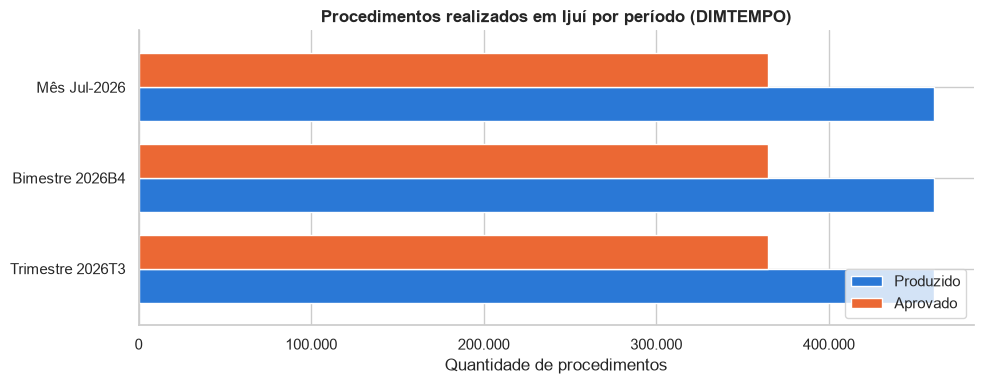

In [13]:
ultimo_mes = tabela["di"].max()
ref = dimtempo.loc[dimtempo["di"] == ultimo_mes].iloc[0]

recortes = {
    ("Calendário", f"Mês {ref['MAExt']}"): (tabela["anomes"] == ref["anomes"], 1),
    ("Calendário", f"Bimestre {ref['anobi']}"): (tabela["anobi"] == ref["anobi"],
                                                 (dimtempo["anobi"] == ref["anobi"]).sum()),
    ("Calendário", f"Trimestre {ref['anotri']}"): (tabela["anotri"] == ref["anotri"],
                                                   (dimtempo["anotri"] == ref["anotri"]).sum()),
}
for n in (2, 3):
    inicio = ultimo_mes - pd.DateOffset(months=n - 1)
    recortes[("Janela móvel", f"Últimos {n} meses ({inicio:%m/%Y}–{ultimo_mes:%m/%Y})")] = (
        tabela["di"].between(inicio, ultimo_mes), n)

linhas = []
for (tipo, periodo), (filtro, meses_periodo) in recortes.items():
    recorte = tabela.loc[filtro]
    linhas.append({
        "Recorte": tipo, "Período": periodo,
        "Cobertura": f"{recorte['anomes'].nunique()}/{meses_periodo} meses",
        "Registros": len(recorte),
        "QtdProduzida": recorte["pa_qtdpro"].sum(),
        "QtdAprovada": recorte["pa_qtdapr"].sum(),
        "ValorAprovado": recorte["pa_valapr"].sum(),
    })
periodos = pd.DataFrame(linhas)
display(periodos)

calendario = periodos[periodos["Recorte"] == "Calendário"]
fig, ax = plt.subplots(figsize=(10, 4))
barras_produzido_aprovado(calendario, "Período", ax, titulo="Procedimentos realizados em Ijuí por período (DIMTEMPO)")
plt.tight_layout()
plt.show()

**Interpretação:** com a carga atual (somente o arquivo **PARS2607**, jul/2026), mês, bimestre e trimestre retornam **o mesmo total**. O bimestre `2026B4` (jul–ago) e o trimestre `2026T3` (jul–set) aparecem com cobertura parcial (1/2 e 1/3 meses). O código já está pronto para mais meses: ao carregar novos arquivos PARS no banco, os recortes se ajustam sozinhos pela DIMTEMPO.

### 3.3 Distribuição por especialidade / tipo de procedimento

**Pergunta:** como a produção se distribui entre consultas, exames de imagem, oncologia, psiquiatria etc.?

A classificação usa a **hierarquia oficial da tabela SIGTAP** do SUS. O código do procedimento tem 10 dígitos e os primeiros já indicam a área:

```
03 04 02 0xxx
│  │  └─ forma de organização (030402 = quimioterapia)
│  └──── subgrupo  (0304 = tratamento em oncologia)
└─────── grupo     (03 = procedimentos clínicos)
```

**De onde vem o código:** a VIEW `pa_ijui` expõe `pa.pa_proc_id AS CodProcedimento`, o mesmo código usado no `JOIN` com a tabela `procedimentos` que traz a descrição. A classificação é, portanto, **exata**: não depende do texto da descrição.

**Onde o código não basta:** o SIGTAP não separa *saúde mental* (psiquiatria e psicologia dependem de quem atende e de onde). Para esse recorte usamos também a **ocupação (CBO)** e o **estabelecimento (CAPS)**, só dentro do grupo 03 (procedimentos clínicos).

In [14]:
# 1) Código SIGTAP vindo da VIEW (pa_proc_id). Conferência de qualidade do código.
tabela["CodProcedimento"] = tabela["CodProcedimento"].fillna("").astype(str).str.strip()

codigo_valido = tabela["CodProcedimento"].str.fullmatch(r"\d{10}")
ligacao = pd.Series({
    "Código SIGTAP válido (10 dígitos) com descrição": (codigo_valido & (tabela["Procedimento"] != "Não informado")).sum(),
    "Código válido sem descrição na tabela procedimentos": (codigo_valido & (tabela["Procedimento"] == "Não informado")).sum(),
    "Código ausente ou inválido": (~codigo_valido).sum(),
}).to_frame("Registros")
ligacao["%"] = (ligacao["Registros"] / len(tabela) * 100).round(2)
display(ligacao)

sem_descricao = tabela.loc[codigo_valido & (tabela["Procedimento"] == "Não informado"), "CodProcedimento"]
if not sem_descricao.empty:
    print("Códigos sem descrição (provável tabela SIGTAP desatualizada em relação à competência do PARS):")
    display(sem_descricao.value_counts().head(10).to_frame("Registros"))

# Textos normalizados (também usados nas Seções 4 e 8).
proc_n = normalizar(tabela["Procedimento"])
ocup_n = normalizar(tabela["Ocupacao"])
eh_caps = tabela["TipoUnidade"].astype(str).str.strip().str.zfill(2).eq("70")   # tipo de unidade CNES 70 = CAPS

,Registros,%
Código SIGTAP válido (10 dígitos) com descrição,68827,100.00
Código válido sem descrição na tabela procedimentos,0,0.00
Código ausente ou inválido,0,0.00


In [15]:
# 2) Área = grupo/subgrupo SIGTAP. As regras são avaliadas em ordem; a primeira que casar vence.
cod = tabela["CodProcedimento"]
c2, c4, c6 = cod.str[:2], cod.str[:4], cod.str[:6]

# Saúde mental: o SIGTAP não separa psiquiatria/psicologia; combina código + ocupação + CAPS (só no grupo 03).
saude_mental = c2.eq("03") & (
    c6.isin(["030108", "030317"])                      # atendimento/acompanhamento psicossocial; urgência em psiquiatria
    | ocup_n.str.contains(r"PSIQUIATRA|PSICOLOG")      # profissional
    | eh_caps                                          # estabelecimento é CAPS (CNES)
    | proc_n.str.contains(r"PSICOSSOCIAL|PSIQUIATR|PSICOTERAP")
)

regras_area = [
    ("Oncologia", c4.isin(["0304", "0416"]) | c6.eq("030312")),   # tratamento em oncologia, cirurgia oncológica, iodoterapia
    ("Saúde mental", saude_mental),
    ("Hemoterapia", c4.isin(["0306", "0212", "0501"])),
    ("Exames laboratoriais", c4.isin(["0202", "0203", "0213", "0214"])),
    ("Exames de imagem", c4.isin(["0204", "0205", "0206", "0207", "0208", "0210"])),
    ("Métodos diagnósticos (especialidades)", c4.isin(["0201", "0209", "0211"])),
    ("Odontologia", c4.isin(["0307", "0414"])),
    ("Reabilitação (fisioterapia)", c4.eq("0302")),
    ("Consultas e atendimentos", c4.eq("0301")),
    ("Outros procedimentos clínicos", c2.eq("03")),
    ("Cirurgias e transplantes", c2.isin(["04", "05"])),
    ("Medicamentos", c2.eq("06")),
    ("OPM (órteses, próteses, materiais)", c2.eq("07")),
    ("Promoção e prevenção", c2.eq("01")),
    ("OCI e ações complementares", c2.isin(["08", "09"])),
]
tabela["Area"] = np.select([c for _, c in regras_area], [n for n, _ in regras_area], default="Código inválido / ausente")

areas = resumo_producao(tabela, "Area").sort_values("QtdAprovada", ascending=False)
areas["% Qtd aprovada"] = (areas["QtdAprovada"] / areas["QtdAprovada"].sum() * 100).round(1)
areas["% Valor aprovado"] = (areas["ValorAprovado"] / areas["ValorAprovado"].sum() * 100).round(1)
display(areas)

,Area,Registros,QtdProduzida,QtdAprovada,ValorProduzido,ValorAprovado,TaxaAprovQtd_%,TaxaAprovValor_%,% Qtd aprovada,% Valor aprovado
5,Medicamentos,6051,"273,648.00","207,594.00","929,283.76","923,000.40",75.90,99.30,56.90,15.00
3,Exames laboratoriais,3361,"76,366.00","70,112.00","399,723.02","353,158.71",91.80,88.40,19.20,5.70
1,Consultas e atendimentos,23364,"57,558.00","46,914.00","331,287.64","269,643.55",81.50,81.40,12.90,4.40
14,Saúde mental,10239,"18,127.00","14,293.00","50,037.60","49,561.40",78.80,99.00,3.90,0.80
6,Métodos diagnósticos (especialidades),16437,"18,548.00","10,131.00","423,206.47","356,700.23",54.60,84.30,2.80,5.80
2,Exames de imagem,4346,"7,383.00","6,477.00","544,258.87","467,855.34",87.70,86.00,1.80,7.60
10,Oncologia,2255,"2,134.00","2,132.00","2,004,544.07","2,000,722.72",99.90,99.80,0.60,32.50
11,Outros procedimentos clínicos,206,"2,013.00","2,013.00","464,567.28","464,567.28",100.00,100.00,0.60,7.50
4,Hemoterapia,187,"1,760.00","1,731.00","25,923.30","25,633.30",98.40,98.90,0.50,0.40
0,Cirurgias e transplantes,1183,"1,671.00","1,671.00","259,023.43","409,485.43",100.00,158.10,0.50,6.60


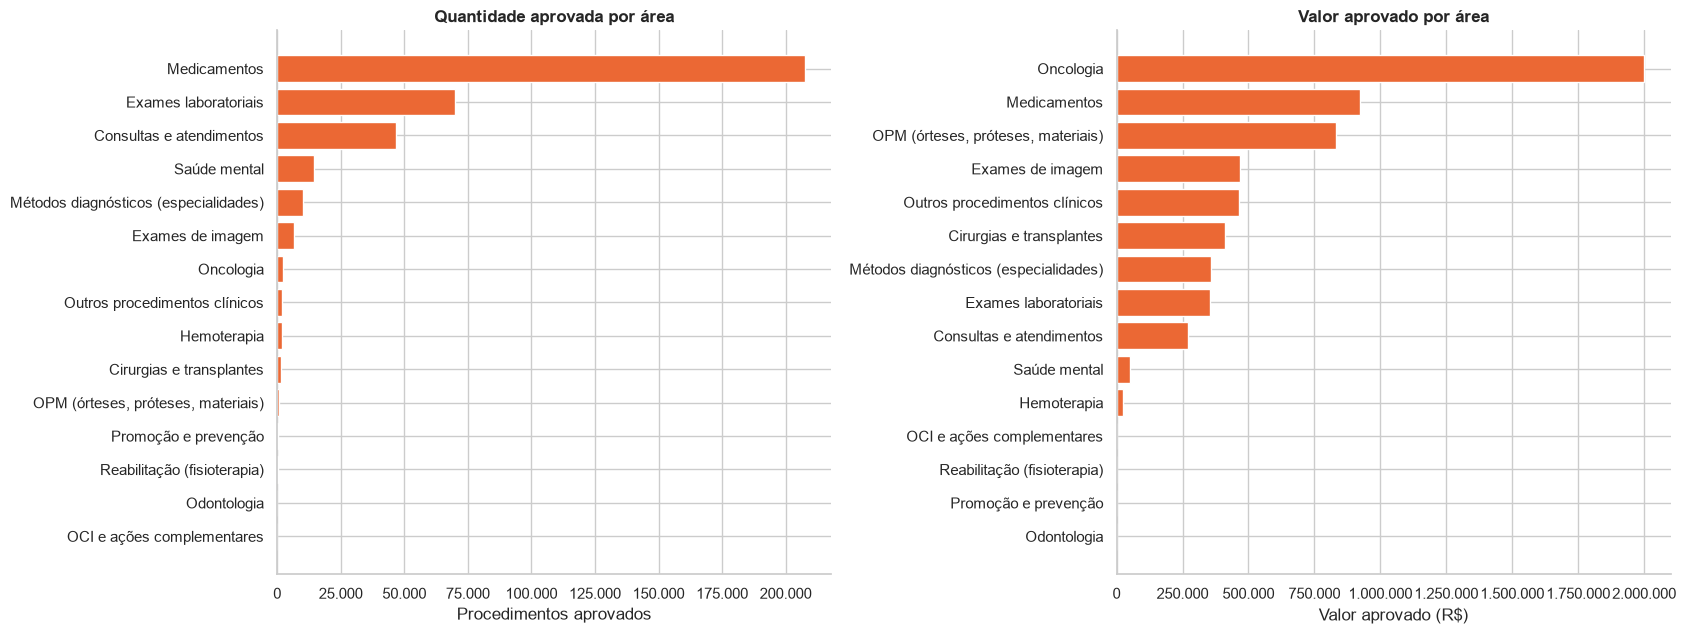

Conferência - subgrupos SIGTAP com maior quantidade aprovada:


,Subgrupo,Area,Registros,QtdAprovada,Exemplo
36,0604,Medicamentos,6051,"207,594.00",SACARATO DE HIDROXIDO FERRICO 100 MG INJETAVEL (POR FRASCO …
3,0202,Exames laboratoriais,3139,"68,447.00",PESQUISA DE ANTICORPOS IGM CONTRA ANTIGENO CENTRAL DO VIRUS…
15,0301,Consultas e atendimentos,23364,"46,914.00",CONSULTA MEDICA EM ATENCAO ESPECIALIZADA
16,0301,Saúde mental,10237,"14,291.00",TRATAMENTO INTENSIVO DE PACIENTE EM REABILITACAO FISICA (1 …
12,0211,Métodos diagnósticos (especialidades),16122,"9,802.00",BIOMICROSCOPIA DE FUNDO DE OLHO
5,0204,Exames de imagem,650,"2,626.00",DENSITOMETRIA OSSEA DUO-ENERGETICA DE COLUNA (VERTEBRAS LOM…
20,0304,Oncologia,2253,"2,130.00",HORMONIOTERAPIA DO ADENOCARCINOMA DE PROSTATA AVANCADO - 1¦…
6,0205,Exames de imagem,1206,"1,783.00",ECOCARDIOGRAFIA TRANSESOFAGICA
21,0305,Outros procedimentos clínicos,196,"1,762.00",HEMODIALISE (MAXIMO 3 SESSOES POR SEMANA)
14,0214,Exames laboratoriais,13,"1,463.00",TESTE RAPIDO PARA DETECCAO DE SARS-COVID-2


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

ordem = areas.sort_values("QtdAprovada")
axes[0].barh(ordem["Area"], ordem["QtdAprovada"], color=COR_APROVADO)
axes[0].set_title("Quantidade aprovada por área")
axes[0].set_xlabel("Procedimentos aprovados")
formatar_eixo(axes[0], "x")

ordem = areas.sort_values("ValorAprovado")
axes[1].barh(ordem["Area"], ordem["ValorAprovado"], color=COR_APROVADO)
axes[1].set_title("Valor aprovado por área")
axes[1].set_xlabel("Valor aprovado (R$)")
formatar_eixo(axes[1], "x")

plt.tight_layout()
plt.show()

# Conferência: subgrupos (4 dígitos) mais frequentes, com um exemplo de procedimento.
subgrupos = (tabela[tabela["CodProcedimento"].str.len() >= 4]
             .assign(Subgrupo=lambda d: d["CodProcedimento"].str[:4])
             .groupby(["Subgrupo", "Area"], as_index=False)
             .agg(Registros=("Procedimento", "size"), QtdAprovada=("pa_qtdapr", "sum"),
                  Exemplo=("Procedimento", "first"))
             .sort_values("QtdAprovada", ascending=False).head(12))
subgrupos["Exemplo"] = subgrupos["Exemplo"].map(lambda s: rotulo_curto(s, 60))
print("Conferência - subgrupos SIGTAP com maior quantidade aprovada:")
display(subgrupos)

**Interpretação:** comparar os dois painéis mostra que **volume e custo não andam juntos**. Em jul/2026, os **medicamentos** (grupo 06, dispensados pela 17ª CRS) somam cerca de **57% da quantidade aprovada**, mas cerca de 15% do valor. A **oncologia** faz o caminho inverso: menos de 1% da quantidade e cerca de **um terço do valor aprovado** (R$ 2,0 milhões). Para o planejamento financeiro, as poucas linhas de alta complexidade pesam mais do que milhares de procedimentos de baixo custo. A tabela de conferência mostra o subgrupo SIGTAP por trás de cada área, o que permite justificar a classificação na apresentação.

### 3.4 Evolução temporal: picos e quedas na demanda

**Pergunta:** a demanda está crescendo ou caindo? Há picos?

A série é montada pela DIMTEMPO (ordenada por `di`), com variação percentual mês a mês (`.pct_change()`).

,di,MAExt,Registros,QtdProduzida,QtdAprovada,ValorProduzido,ValorAprovado,TaxaAprovQtd_%,TaxaAprovValor_%,Variação QtdAprovada_%
0,2026-07-01,Jul-2026,68827,"461,059.00","364,679.00","6,272,060.94","6,158,024.69",79.10,98.20,NaN


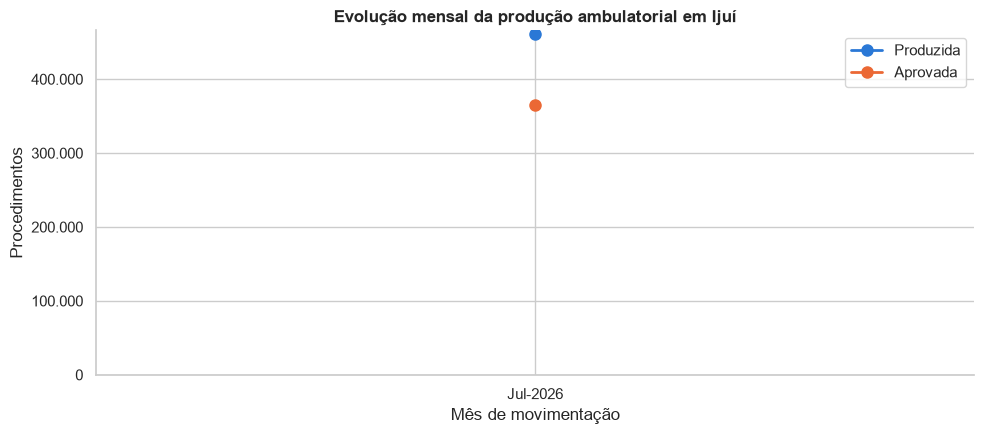

ATENÇÃO: a base possui apenas 1 mês de movimentação. Não é possível identificar tendência, picos ou quedas; carregue mais arquivos PARS para esta análise.


In [17]:
mensal = resumo_producao(tabela, ["di", "MAExt"]).sort_values("di").reset_index(drop=True)
mensal["Variação QtdAprovada_%"] = (mensal["QtdAprovada"].pct_change() * 100).round(1)
display(mensal)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(mensal["MAExt"], mensal["QtdProduzida"], marker="o", linewidth=2, markersize=8,
        color=COR_PRODUZIDO, label="Produzida")
ax.plot(mensal["MAExt"], mensal["QtdAprovada"], marker="o", linewidth=2, markersize=8,
        color=COR_APROVADO, label="Aprovada")
ax.set_title("Evolução mensal da produção ambulatorial em Ijuí")
ax.set_xlabel("Mês de movimentação")
ax.set_ylabel("Procedimentos")
ax.set_ylim(bottom=0)
formatar_eixo(ax, "y")
ax.legend()
plt.tight_layout()
plt.show()

if len(mensal) < 2:
    print("ATENÇÃO: a base possui apenas 1 mês de movimentação. Não é possível identificar "
          "tendência, picos ou quedas; carregue mais arquivos PARS para esta análise.")
else:
    # Picos e quedas por área: variação do último mês em relação ao anterior.
    por_area_mes = tabela.pivot_table(index="Area", columns="di", values="pa_qtdapr", aggfunc="sum", fill_value=0)
    variacao = por_area_mes.pct_change(axis=1).mul(100).iloc[:, 1:]
    variacao.columns = [f"{c:%m/%Y}" for c in variacao.columns]
    plt.figure(figsize=(1.6 * variacao.shape[1] + 6, 6))
    sns.heatmap(variacao.replace([np.inf, -np.inf], np.nan), annot=True, fmt=".0f",
                cmap="RdBu_r", center=0, cbar_kws={"label": "Variação % vs mês anterior"})
    plt.title("Picos (vermelho) e quedas (azul) por área")
    plt.xlabel("Mês")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

#### Mês do atendimento (competência) × mês de processamento (movimentação)

A VIEW se relaciona com a DIMTEMPO pelo **mês de movimentação** (`pa_mvm`, quando o SUS processou a produção). O **mês em que o atendimento aconteceu** é a **competência** (`Competencia` = `pa_cmp`). O estabelecimento pode apresentar produção de meses anteriores com atraso, até o limite permitido pelas regras do SIA.

In [18]:
competencia = (tabela.assign(Competencia=tabela["Competencia"].astype(str).str.strip())
                     .groupby("Competencia")
                     .agg(Registros=("Procedimento", "size"), QtdAprovada=("pa_qtdapr", "sum"),
                          ValorAprovado=("pa_valapr", "sum"))
                     .sort_index())
competencia["% Valor aprovado"] = (competencia["ValorAprovado"] / competencia["ValorAprovado"].sum() * 100).round(1)
display(competencia)

com_atraso = tabela["Competencia"].astype(str).str.strip() != tabela["anomes"].astype(str)
print(f"Produção apresentada com atraso (competência anterior ao mês de movimentação): "
      f"{br_num(com_atraso.sum())} registros "
      f"({br_pct(tabela.loc[com_atraso, 'pa_valapr'].sum() / tabela['pa_valapr'].sum() * 100)} do valor aprovado)")

,Registros,QtdAprovada,ValorAprovado,% Valor aprovado
Competencia,,,,
202605,10,2.00,320.00,0.00
202606,152,438.00,"38,467.36",0.60
202607,68665,"364,239.00","6,119,237.33",99.40


Produção apresentada com atraso (competência anterior ao mês de movimentação): 162 registros (0,6% do valor aprovado)


**Interpretação:** com apenas jul/2026 carregado, a série mensal tem **um único ponto**, então não é possível afirmar tendência, picos ou quedas. Esta é a principal limitação da base atual. Quando mais meses forem carregados (por exemplo, `PARS2604a/b`, `PARS2605a/b` e `PARS2606a/b`), o gráfico de linhas e o mapa de calor por área passam a mostrar onde a demanda cresce ou cai. A tabela de competência mostra quanto da produção processada em julho foi **realizada em meses anteriores**. Esse atraso precisa ser lembrado ao interpretar "picos": um mês com muita produção atrasada parece um pico de demanda, mas pode ser só regularização de faturamento.

---
## 4. Produção por estabelecimento de saúde

### 4.1 Ranking de produção

**Pergunta:** quais estabelecimentos mais produzem (HCI, Hospital Bom Pastor, UBS, clínicas conveniadas…)?

Os estabelecimentos são agrupados pelo **tipo de unidade do CNES** (`TipoUnidade` = `pa_tpups`), a classificação oficial do cadastro de estabelecimentos.

In [19]:
TIPOS_UNIDADE = {
    "01": "Posto de saúde", "02": "UBS / Centro de saúde", "04": "Policlínica",
    "05": "Hospital geral", "07": "Hospital especializado", "15": "Unidade mista",
    "20": "Pronto-socorro geral", "21": "Pronto-socorro especializado", "22": "Consultório isolado",
    "36": "Clínica / centro de especialidade", "39": "Apoio diagnóstico e terapia (SADT)",
    "42": "Unidade móvel de urgência (SAMU)", "43": "Farmácia", "50": "Vigilância em saúde",
    "62": "Hospital-dia", "68": "Central de gestão em saúde", "69": "Centro de hemoterapia",
    "70": "CAPS", "71": "Apoio à saúde da família", "73": "Pronto atendimento (UPA)",
    "77": "Atenção domiciliar", "79": "Oficina ortopédica",
}
tabela["TipoUnidade"] = tabela["TipoUnidade"].astype(str).str.strip().str.zfill(2)
tabela["TipoEstabelecimento"] = tabela["TipoUnidade"].map(TIPOS_UNIDADE).fillna("Outro (código " + tabela["TipoUnidade"] + ")")

print("Tipos de unidade presentes:")
display(tabela.groupby(["TipoUnidade", "TipoEstabelecimento"])["Estabelecimento"].nunique()
              .to_frame("Estabelecimentos"))

ranking = resumo_producao(tabela, ["Estabelecimento", "TipoEstabelecimento"]).sort_values("QtdAprovada", ascending=False)
ranking.insert(0, "Posição", range(1, len(ranking) + 1))
display(ranking.head(15))

por_tipo = resumo_producao(tabela, "TipoEstabelecimento").sort_values("QtdAprovada", ascending=False)
display(por_tipo)

Tipos de unidade presentes:


,,Estabelecimentos
TipoUnidade,TipoEstabelecimento,
05,Hospital geral,2
36,Clínica / centro de especialidade,4
39,Apoio diagnóstico e terapia (SADT),5
42,Unidade móvel de urgência (SAMU),2
68,Central de gestão em saúde,1
70,CAPS,3
73,Pronto atendimento (UPA),1


,Posição,Estabelecimento,TipoEstabelecimento,Registros,QtdProduzida,QtdAprovada,ValorProduzido,ValorAprovado,TaxaAprovQtd_%,TaxaAprovValor_%
0,1,17 COORDENADORIA REGIONAL DE SAUDE,Central de gestão em saúde,6051,"273,648.00","207,594.00","929,283.76","923,000.40",75.90,99.30
11,2,HOSPITAL DE CLINICAS IJUI,Hospital geral,24241,"45,877.00","38,117.00","3,566,157.48","3,443,895.19",83.10,96.60
12,3,LABORATORIO DE ANALISES CLINICAS UNILAB,Apoio diagnóstico e terapia (SADT),300,"29,720.00","29,720.00","147,391.43","147,391.43",100.00,100.00
8,4,CISA,Apoio diagnóstico e terapia (SADT),1766,"30,553.00","24,659.00","217,267.85","167,357.92",80.70,77.00
17,5,UNIDADE DE PRONTO ATENDIMENTO DR MARTIN CESAR AGNOLETTO,Pronto atendimento (UPA),235,"24,915.00","21,566.00","68,317.20","65,916.54",86.60,96.50
10,6,HOSPITAL BOM PASTOR IJUI,Hospital geral,19158,"19,162.00","10,169.00","353,851.47","431,713.92",53.10,122.00
9,7,HEMOVITA,Apoio diagnóstico e terapia (SADT),159,"8,117.00","8,117.00","42,124.13","42,124.13",100.00,100.00
4,8,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CAPS,4326,"8,005.00","5,184.00","4,624.20","4,624.20",64.80,100.00
5,9,CENTRO DE ATENCAO PSICOSSOCIAL CAPS INFANTIL CARAMELO,CAPS,2825,"4,215.00","3,447.00","4,002.10","4,002.10",81.80,100.00
3,10,CENTRO DE ATENCAO PSICOSSOCIAL CAPS COLMEIA,CAPS,1048,"3,494.00","3,324.00","9,161.82","9,161.82",95.10,100.00


,TipoEstabelecimento,Registros,QtdProduzida,QtdAprovada,ValorProduzido,ValorAprovado,TaxaAprovQtd_%,TaxaAprovValor_%
2,Central de gestão em saúde,6051,"273,648.00","207,594.00","929,283.76","923,000.40",75.90,99.30
0,Apoio diagnóstico e terapia (SADT),2378,"71,557.00","65,663.00","425,448.46","375,538.53",91.80,88.30
4,Hospital geral,43399,"65,039.00","48,286.00","3,920,008.95","3,875,609.11",74.20,98.90
5,Pronto atendimento (UPA),235,"24,915.00","21,566.00","68,317.20","65,916.54",86.60,96.50
1,CAPS,8199,"15,714.00","11,955.00","17,788.12","17,788.12",76.10,100.00
3,Clínica / centro de especialidade,8480,"9,598.00","9,027.00","910,253.65","899,211.19",94.10,98.80
6,Unidade móvel de urgência (SAMU),85,588.00,588.00,960.80,960.80,100.00,100.00


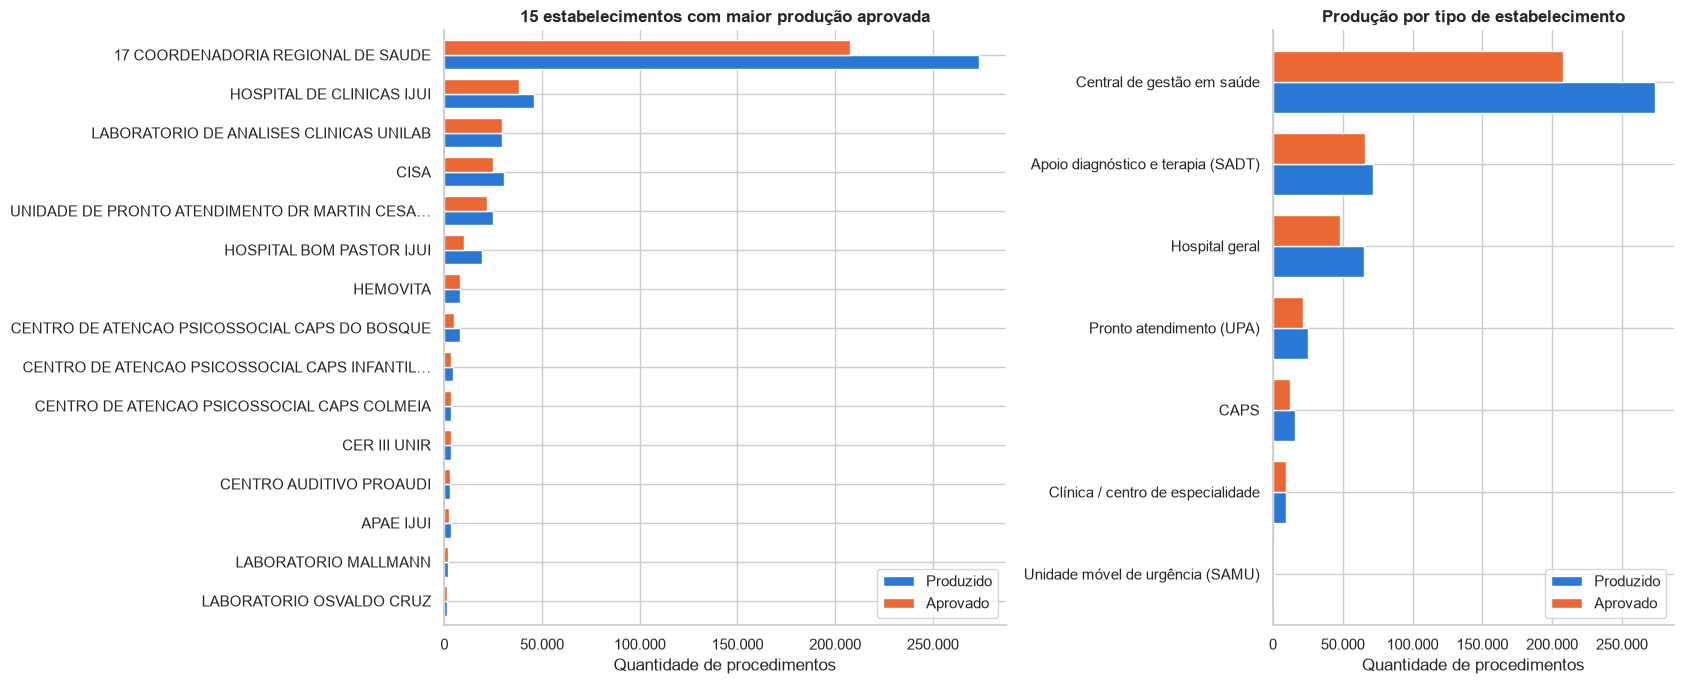

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [1.4, 1]})

top15 = ranking.head(15)
barras_produzido_aprovado(top15, "Estabelecimento", axes[0],
                          titulo="15 estabelecimentos com maior produção aprovada")

barras_produzido_aprovado(por_tipo, "TipoEstabelecimento", axes[1],
                          titulo="Produção por tipo de estabelecimento")

plt.tight_layout()
plt.show()

### 4.2 Aprovados × produzidos

**Pergunta:** quanto da produção apresentada por cada estabelecimento foi aprovada?

A **taxa de aprovação** = quantidade aprovada ÷ quantidade produzida. Valores abaixo de 100% indicam procedimentos glosados ou rejeitados (por exemplo, por teto financeiro, falta de habilitação, inconsistência cadastral ou ultrapassagem de limite de APAC).

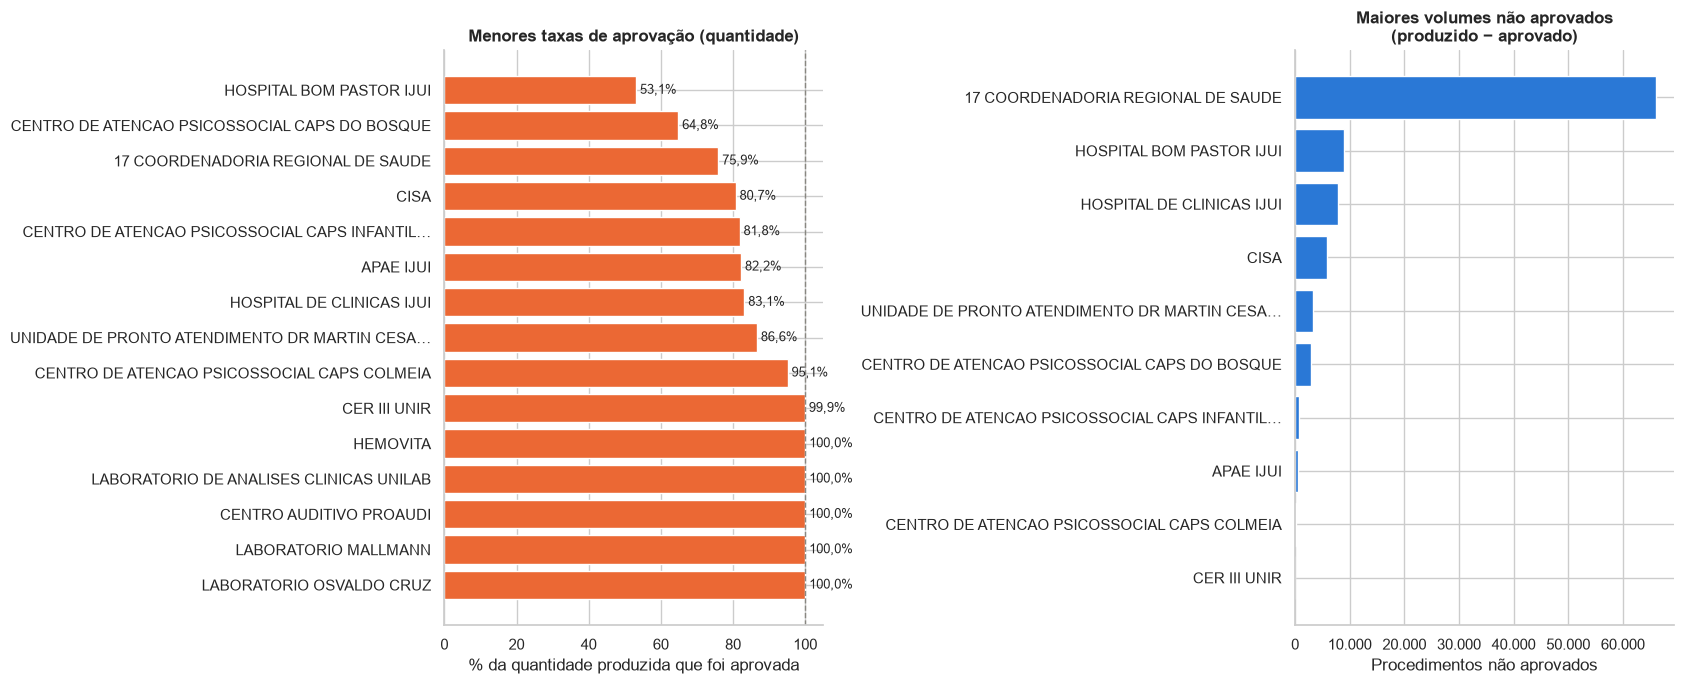

Taxa geral de aprovação (quantidade): 79,1%


In [21]:
relevantes = ranking[ranking["QtdProduzida"] >= 500].copy()      # evita taxas de estabelecimentos muito pequenos
relevantes["NaoAprovada"] = relevantes["QtdProduzida"] - relevantes["QtdAprovada"]

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

taxa = relevantes.sort_values("TaxaAprovQtd_%", ascending=True).head(15).iloc[::-1]
axes[0].barh(taxa["Estabelecimento"].map(rotulo_curto), taxa["TaxaAprovQtd_%"], color=COR_APROVADO)
axes[0].axvline(100, color=COR_NEUTRA, linestyle="--", linewidth=1)
axes[0].set_title("Menores taxas de aprovação (quantidade)")
axes[0].set_xlabel("% da quantidade produzida que foi aprovada")
for i, v in enumerate(taxa["TaxaAprovQtd_%"]):
    axes[0].text(v, i, " " + br_pct(v), va="center", fontsize=9)

nao_aprov = relevantes.nlargest(10, "NaoAprovada").iloc[::-1]
axes[1].barh(nao_aprov["Estabelecimento"].map(rotulo_curto), nao_aprov["NaoAprovada"], color=COR_PRODUZIDO)
axes[1].set_title("Maiores volumes não aprovados\n(produzido − aprovado)")
axes[1].set_xlabel("Procedimentos não aprovados")
formatar_eixo(axes[1], "x")

plt.tight_layout()
plt.show()

total_prod, total_aprov = tabela["pa_qtdpro"].sum(), tabela["pa_qtdapr"].sum()
print(f"Taxa geral de aprovação (quantidade): {br_pct(total_aprov / total_prod * 100)}")

**Interpretação:** os dois hospitais (**HCI** e **Hospital Bom Pastor**) concentram a maior parte dos **registros**, e o HCI sozinho responde por mais da metade do **valor aprovado**. Já a **17ª Coordenadoria Regional de Saúde** lidera em **quantidade**: todos os seus registros são **dispensação de medicamentos**, contados por comprimido ou frasco. Os destaques de aprovação em jul/2026:

- **Hospital Bom Pastor:** só cerca de **53% da quantidade** produzida foi aprovada, mas o **valor aprovado ficou cerca de 22% acima do produzido**. A combinação sugere que a glosa recai sobre procedimentos baratos, enquanto incentivos ou complementos elevam o valor aprovado. É um caso a conferir com o faturamento.
- **CAPS do Bosque:** cerca de **65%** da quantidade aprovada. Como os valores unitários dos CAPS são baixos, a perda financeira é pequena, mas a produção não reconhecida subestima a atividade da rede de saúde mental.
- **17ª CRS e CISA:** perdem em torno de 20–25% da quantidade.

O gráfico da esquerda aponta onde a perda **proporcional** é maior; o da direita mostra onde está o maior volume **absoluto** não aprovado.

---
## 5. Perfil demográfico e epidemiológico

### 5.1 Sexo e faixa etária

**Pergunta:** quem é a população atendida?

A contagem é de **registros** (não de pacientes distintos, pois a VIEW não identifica o paciente). Registros sem sexo/idade válidos ficam como "Não informado".

,Registros,%
Sexo,,
Feminino,33636,48.90
Masculino,32401,47.10
Não informado,2790,4.10


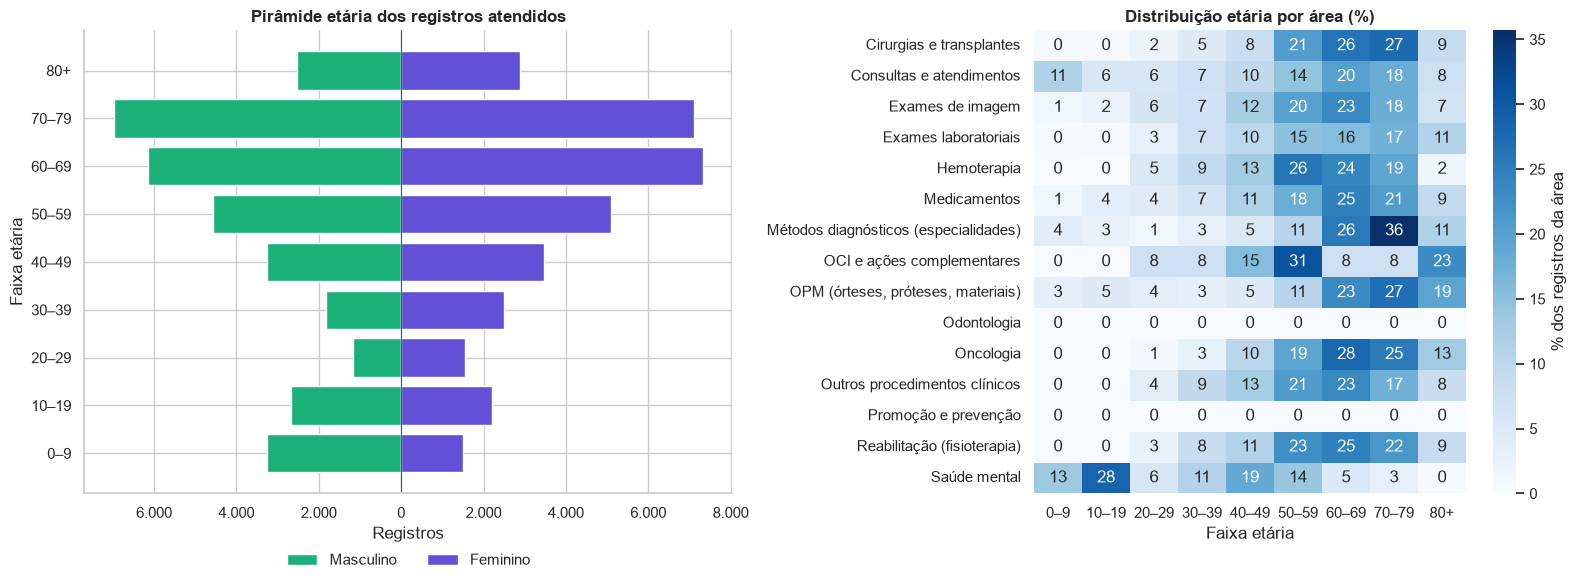

In [22]:
sexo = tabela["Sexo"].value_counts().to_frame("Registros")
sexo["%"] = (sexo["Registros"] / sexo["Registros"].sum() * 100).round(1)
display(sexo)

piramide = (pd.crosstab(tabela["FaixaEtaria"], tabela["Sexo"])
              .reindex(index=ROTULOS_FAIXA, columns=["Masculino", "Feminino"], fill_value=0))

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.2, 1]})

ax = axes[0]
ax.barh(piramide.index, -piramide["Masculino"], color=COR_MASCULINO, label="Masculino")
ax.barh(piramide.index, piramide["Feminino"], color=COR_FEMININO, label="Feminino")
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: br_num(abs(v))))
ax.set_title("Pirâmide etária dos registros atendidos")
ax.set_xlabel("Registros")
ax.set_ylabel("Faixa etária")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)

# Área x faixa etária: em que idade cada área concentra seus atendimentos (% da linha).
area_faixa = pd.crosstab(tabela["Area"], tabela["FaixaEtaria"], normalize="index").mul(100)
area_faixa = area_faixa.reindex(columns=ROTULOS_FAIXA, fill_value=0)
sns.heatmap(area_faixa, annot=True, fmt=".0f", cmap="Blues", ax=axes[1],
            cbar_kws={"label": "% dos registros da área"})
axes[1].set_title("Distribuição etária por área (%)")
axes[1].set_xlabel("Faixa etária")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Interpretação:** a pirâmide mostra o equilíbrio entre os sexos e a concentração em adultos e idosos, típica da atenção especializada. O mapa de calor ajuda no planejamento por público. Áreas como **oncologia** e **exames por métodos diagnósticos** se concentram nas faixas acima de 50 anos. A **saúde mental** (CAPS infantil) e a **reabilitação** (APAE, CER) têm peso relevante entre crianças e jovens.

### 5.2 Principais diagnósticos (CID-10)

**Pergunta:** quais diagnósticos motivam os atendimentos? Qual é o peso das doenças crônicas (hipertensão, diabetes, câncer…)?

Os CIDs são agrupados em **capítulos** da CID-10 e em **grupos de interesse** para a gestão. São considerados apenas os registros com CID válido.

Registros com CID válido: 22.014 (32,0% do total)


,Registros,QtdAprovada,ValorAprovado
Transtornos mentais (F00–F99),4674,"34,638.00","54,108.37"
Neoplasias / câncer (C00–D48),2611,"2,595.00","2,039,065.99"
DPOC e asma (J44–J45),1536,"24,989.00","743,918.08"
Diabetes (E10–E14),541,"2,646.00","1,723.21"
Cardiopatia isquêmica (I20–I25),518,"1,148.00","240,891.08"
Insuficiência cardíaca (I50),207,"4,506.00","16,895.49"
Doença renal crônica (N18),171,"1,419.00",969.79
Hipertensão (I10–I15),1,1.00,6.30


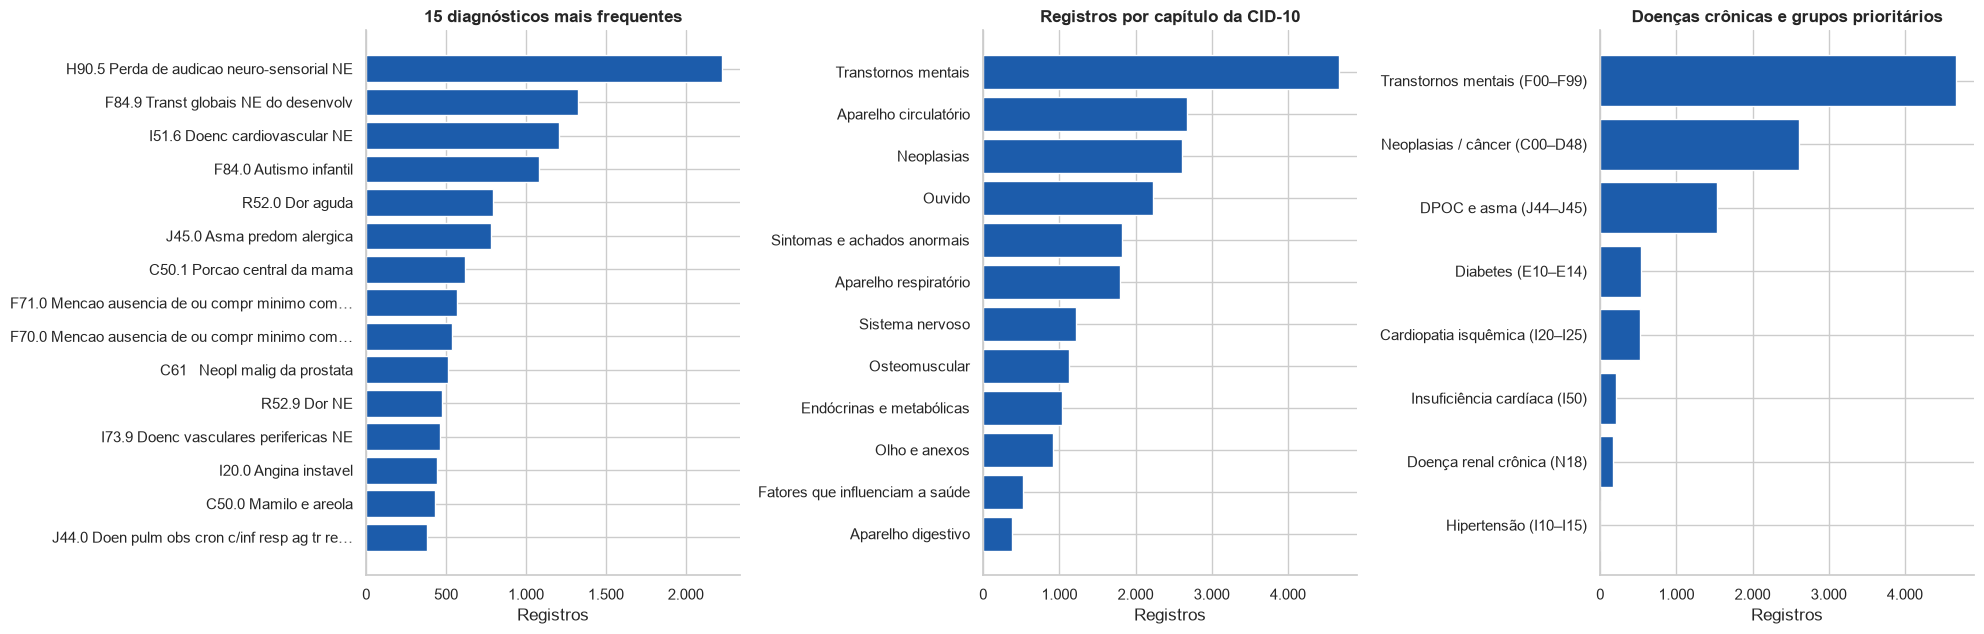

In [23]:
com_cid = tabela[tabela["CID"] != "Não informado"].copy()
print(f"Registros com CID válido: {br_num(len(com_cid))} "
      f"({br_pct(len(com_cid) / len(tabela) * 100)} do total)")

cid3 = com_cid["CID"].str[:3]

CAPITULOS = [
    ("A00", "B99", "Infecciosas e parasitárias"), ("C00", "D48", "Neoplasias"),
    ("D50", "D89", "Sangue e imunidade"), ("E00", "E90", "Endócrinas e metabólicas"),
    ("F00", "F99", "Transtornos mentais"), ("G00", "G99", "Sistema nervoso"),
    ("H00", "H59", "Olho e anexos"), ("H60", "H95", "Ouvido"),
    ("I00", "I99", "Aparelho circulatório"), ("J00", "J99", "Aparelho respiratório"),
    ("K00", "K93", "Aparelho digestivo"), ("L00", "L99", "Pele"),
    ("M00", "M99", "Osteomuscular"), ("N00", "N99", "Geniturinário"),
    ("O00", "O99", "Gravidez, parto e puerpério"), ("P00", "P96", "Perinatais"),
    ("Q00", "Q99", "Malformações congênitas"), ("R00", "R99", "Sintomas e achados anormais"),
    ("S00", "T98", "Lesões e envenenamentos"), ("V01", "Y98", "Causas externas"),
    ("Z00", "Z99", "Fatores que influenciam a saúde"), ("U00", "U99", "Códigos especiais"),
]
com_cid["Capitulo"] = np.select([cid3.between(a, b) for a, b, _ in CAPITULOS],
                                [n for _, _, n in CAPITULOS], default="Outros")

GRUPOS_CRONICOS = {
    "Hipertensão (I10–I15)": cid3.between("I10", "I15"),
    "Diabetes (E10–E14)": cid3.between("E10", "E14"),
    "Neoplasias / câncer (C00–D48)": cid3.between("C00", "D48"),
    "Cardiopatia isquêmica (I20–I25)": cid3.between("I20", "I25"),
    "Insuficiência cardíaca (I50)": cid3 == "I50",
    "Doença renal crônica (N18)": cid3 == "N18",
    "DPOC e asma (J44–J45)": cid3.between("J44", "J45"),
    "Transtornos mentais (F00–F99)": cid3.between("F00", "F99"),
}
cronicos = pd.DataFrame({
    "Registros": {g: m.sum() for g, m in GRUPOS_CRONICOS.items()},
    "QtdAprovada": {g: com_cid.loc[m, "pa_qtdapr"].sum() for g, m in GRUPOS_CRONICOS.items()},
    "ValorAprovado": {g: com_cid.loc[m, "pa_valapr"].sum() for g, m in GRUPOS_CRONICOS.items()},
}).sort_values("Registros", ascending=False)
display(cronicos)

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))

top_cid = com_cid["Diagnostico"].value_counts().head(15).iloc[::-1]
axes[0].barh(top_cid.index.map(rotulo_curto), top_cid.values, color=COR_SERIE)
axes[0].set_title("15 diagnósticos mais frequentes")
axes[0].set_xlabel("Registros")
formatar_eixo(axes[0], "x")

capitulos = com_cid["Capitulo"].value_counts().head(12).iloc[::-1]
axes[1].barh(capitulos.index, capitulos.values, color=COR_SERIE)
axes[1].set_title("Registros por capítulo da CID-10")
axes[1].set_xlabel("Registros")
formatar_eixo(axes[1], "x")

c = cronicos["Registros"].iloc[::-1]
axes[2].barh(c.index, c.values, color=COR_SERIE)
axes[2].set_title("Doenças crônicas e grupos prioritários")
axes[2].set_xlabel("Registros")
formatar_eixo(axes[2], "x")

plt.tight_layout()
plt.show()

**Interpretação:** só cerca de **um terço** dos registros traz CID válido, quase todos de **APAC** (Seção 1.3). Por isso o perfil de diagnósticos reflete a **alta complexidade**: neoplasias (quimioterapia e radioterapia) e as doenças tratadas com medicamentos especializados (artrite reumatoide, asma, diabetes). **Hipertensão aparece em apenas 1 registro** em jul/2026, e **diabetes** aparece quase só na dispensação de insulinas pela 17ª CRS. O acompanhamento dessas doenças crônicas é feito na atenção básica, registrada no **SISAB/e-SUS APS**, e não no SIA. A ausência delas aqui reflete o sistema de informação, e não a prevalência na população.

---
## 6. Fluxos regionais e acesso

**Perguntas:** de quais municípios vêm os pacientes atendidos em Ijuí? Quantos atendimentos são de moradores de outros municípios?

O campo `MunicipioPaciente` é a residência do paciente; `MunicipioEstabelecimento` é sempre Ijuí (filtro da VIEW).

In [24]:
mun_pac_n = normalizar(tabela["MunicipioPaciente"])
# Município "Invalido" (código 999999, UF XX) e "Municipio Ignorado" = origem não informada.
# Em jul/2026 são os registros de BPA consolidado, que não identificam o paciente.
origem_nao_informada = (
    (tabela["MunicipioPaciente"] == "Não informado")
    | mun_pac_n.str.contains(r"INVALIDO|IGNORADO")
    | tabela["UFPaciente"].astype(str).str.strip().isin(["XX", "", "None"])
)
tabela["Origem"] = np.select(
    [mun_pac_n == "IJUI", origem_nao_informada],
    ["Ijuí", "Não informado"], default="Outros municípios")

origem = resumo_producao(tabela, "Origem").set_index("Origem")
participacao = origem[["Registros", "QtdAprovada", "ValorAprovado"]].div(
    origem[["Registros", "QtdAprovada", "ValorAprovado"]].sum()).mul(100).round(1)
display(origem[["Registros", "QtdAprovada", "ValorAprovado"]])
print("Participação (%):")
display(participacao)

outros = tabela[tabela["Origem"] == "Outros municípios"]
print(f"Municípios de origem distintos (exceto Ijuí): {outros['MunicipioPaciente'].nunique()}")

,Registros,QtdAprovada,ValorAprovado
Origem,,,
Ijuí,34066,"103,366.00","1,658,767.61"
Não informado,2790,"111,016.00","560,014.47"
Outros municípios,31971,"150,297.00","3,939,242.61"


Participação (%):


,Registros,QtdAprovada,ValorAprovado
Origem,,,
Ijuí,49.50,28.30,26.90
Não informado,4.10,30.40,9.10
Outros municípios,46.50,41.20,64.00


Municípios de origem distintos (exceto Ijuí): 179


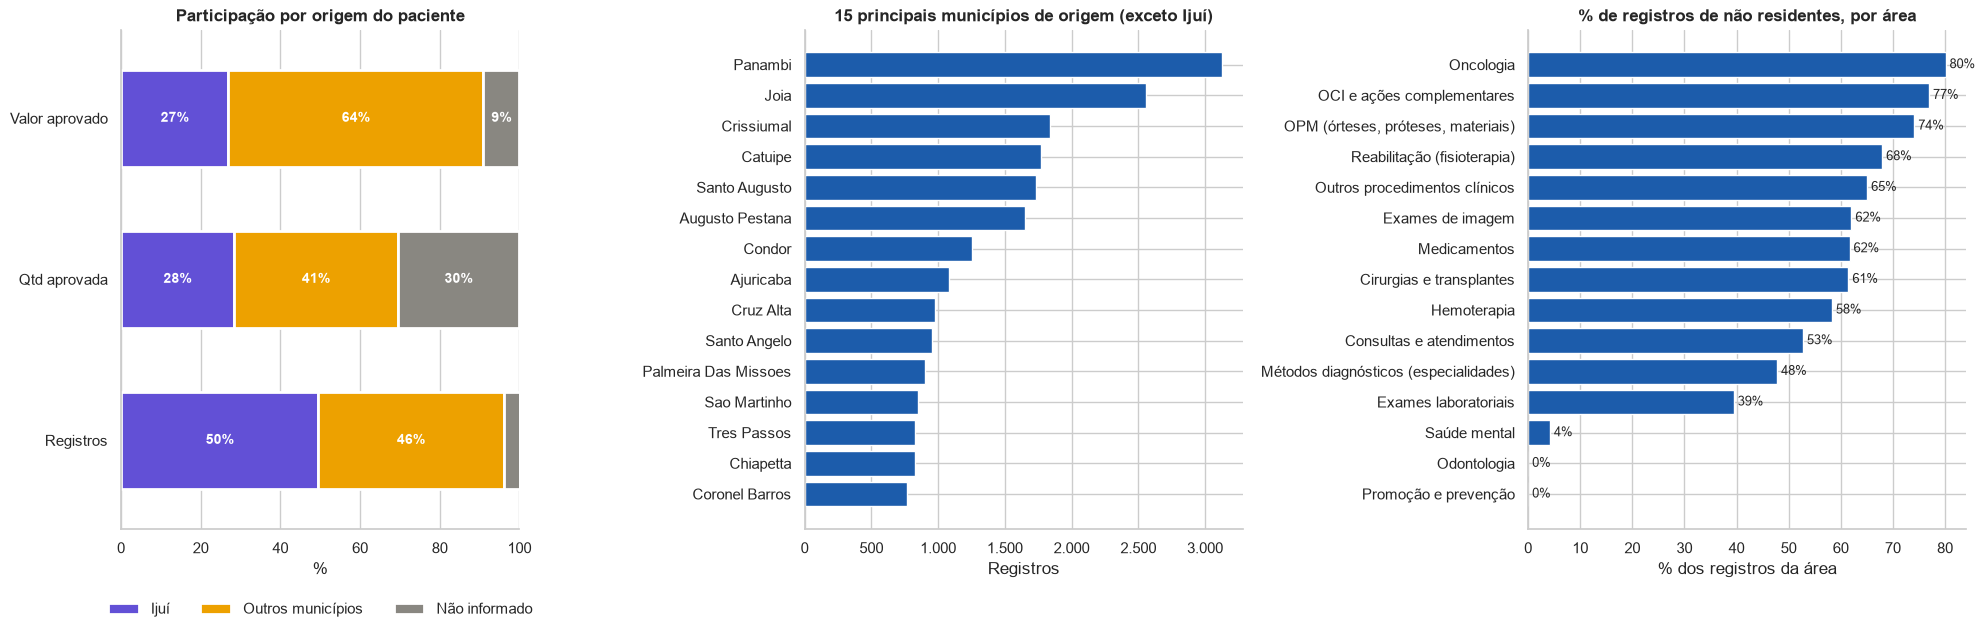

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6.5), gridspec_kw={"width_ratios": [1, 1.1, 1.1]})

# 1) Participação de Ijuí x outros municípios (barras 100% empilhadas).
cores_origem = {"Ijuí": COR_FEMININO, "Outros municípios": "#eda100", "Não informado": COR_NEUTRA}
part = participacao.T.rename(index={"Registros": "Registros", "QtdAprovada": "Qtd aprovada",
                                    "ValorAprovado": "Valor aprovado"})
part = part[[c for c in ["Ijuí", "Outros municípios", "Não informado"] if c in part.columns]]
part.plot(kind="barh", stacked=True, ax=axes[0], color=[cores_origem[c] for c in part.columns],
          width=0.6, edgecolor="white", linewidth=2)
for i, linha in enumerate(part.itertuples(index=False)):
    acumulado = 0
    for v in linha:
        if v >= 6:
            axes[0].text(acumulado + v / 2, i, f"{v:.0f}%", ha="center", va="center",
                         color="white", fontsize=10, fontweight="bold")
        acumulado += v
axes[0].set_xlim(0, 100)
axes[0].set_title("Participação por origem do paciente")
axes[0].set_xlabel("%")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)

# 2) 15 municípios de origem (exceto Ijuí).
top_mun = outros["MunicipioPaciente"].value_counts().head(15).iloc[::-1]
axes[1].barh(top_mun.index, top_mun.values, color=COR_SERIE)
axes[1].set_title("15 principais municípios de origem (exceto Ijuí)")
axes[1].set_xlabel("Registros")
formatar_eixo(axes[1], "x")

# 3) Quais áreas mais atraem pacientes de fora?
area_origem = pd.crosstab(tabela["Area"], tabela["Origem"], normalize="index").mul(100)
fora = area_origem.get("Outros municípios", pd.Series(0, index=area_origem.index)).sort_values()
axes[2].barh(fora.index, fora.values, color=COR_SERIE)
axes[2].set_title("% de registros de não residentes, por área")
axes[2].set_xlabel("% dos registros da área")
for i, v in enumerate(fora.values):
    axes[2].text(v, i, f" {v:.0f}%", va="center", fontsize=9)

plt.tight_layout()
plt.show()

**Interpretação:** Ijuí é **polo regional**. Em jul/2026, cerca de **46% dos registros**, mas cerca de **64% do valor aprovado**, são de moradores de **outros municípios**. Outros cerca de 9% do valor não têm origem informada (BPA consolidado). O valor pesa mais que os registros porque os pacientes de fora procuram justamente os serviços **mais caros**, como a **oncologia do HCI**, com cerca de **80% dos registros de fora de Ijuí**. O terceiro gráfico mostra essas áreas no topo. Para a Secretaria, isso pesa em pactuação (PPI), dimensionamento de oferta e negociação de contrapartidas: boa parte da capacidade instalada em Ijuí atende a região. A Seção 6.2 detalha **de quais regiões** vêm esses pacientes.

### 6.2 Fluxos por Região de Saúde e Macrorregião de Saúde

**Perguntas:** os pacientes de fora vêm da própria região de Ijuí ou de outras regiões do estado? Quais serviços atraem pacientes de mais longe?

O SUS organiza o atendimento em **Regiões de Saúde** (no RS, 30 regiões) agrupadas em **Macrorregiões de Saúde** (7 no RS). Ijuí fica na **Região 13 – Diversidade**, dentro da **Macrorregião Missioneira**. A VIEW relaciona o município do paciente à sua região (`rl_municip_regsaud` → `tb_regsaud`) e à sua macrorregião (`rl_municip_macsaud` → `tb_macsaud`), seguindo o modelo **MUNICIPIO → RL** do enunciado.

Cada registro recebe uma **origem regional**, da mais próxima para a mais distante:

| Origem regional | Significado |
|---|---|
| Ijuí | Morador do próprio município |
| Região 13 (exceto Ijuí) | Demais municípios da Região de Saúde de Ijuí |
| Macro Missioneira (outras regiões) | Outras Regiões de Saúde da mesma macrorregião |
| Outras macrorregiões do RS | Resto do estado |
| Outros estados | Pacientes de fora do RS |
| Não informado | Sem município válido (BPA consolidado) |

**Por que não a microrregião IBGE:** na base territorial do DATASUS (jun/2026), 497 dos 498 municípios do RS apontam para o código `43900` em `rl_municip_micibge`, que **não existe** em `tb_micibge`, porque o IBGE substituiu as microrregiões pelas Regiões Geográficas Imediatas em 2017. A **Macrorregião de Saúde** substitui esse nível com vantagem: é a divisão usada no planejamento do SUS.

In [26]:
def corrigir_acentos(texto):
    """Corrige nomes gravados com codificação trocada (ex.: 'RegiÃ£o' -> 'Região')."""
    texto = str(texto)
    if "Ã" in texto or "Â" in texto:
        try:
            return texto.encode("latin1").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            return texto
    return texto


for coluna in ["RegiaoSaudePaciente", "MacrorregiaoPaciente"]:
    tabela[coluna] = tabela[coluna].fillna("Não informado").map(corrigir_acentos).str.strip()

# Região e macrorregião de Ijuí, identificadas pelos próprios moradores de Ijuí.
REGIAO_IJUI = tabela.loc[tabela["Origem"] == "Ijuí", "RegiaoSaudePaciente"].mode().iloc[0]
MACRO_IJUI = tabela.loc[tabela["Origem"] == "Ijuí", "MacrorregiaoPaciente"].mode().iloc[0]
print("Região de Saúde de Ijuí:", REGIAO_IJUI, "| Macrorregião:", MACRO_IJUI)

ORDEM_ORIGEM = ["Ijuí", "Região 13 (exceto Ijuí)", "Macro Missioneira (outras regiões)",
                "Outras macrorregiões do RS", "Outros estados", "Não informado"]
uf_pac = tabela["UFPaciente"].astype(str).str.strip()
tabela["OrigemRegional"] = np.select(
    [tabela["Origem"] == "Ijuí",
     tabela["Origem"] == "Não informado",
     uf_pac.ne("RS"),
     tabela["RegiaoSaudePaciente"] == REGIAO_IJUI,
     tabela["MacrorregiaoPaciente"] == MACRO_IJUI],
    ["Ijuí", "Não informado", "Outros estados", "Região 13 (exceto Ijuí)", "Macro Missioneira (outras regiões)"],
    default="Outras macrorregiões do RS")

origem_regional = (resumo_producao(tabela, "OrigemRegional").set_index("OrigemRegional")
                   .reindex(ORDEM_ORIGEM).dropna(how="all"))
part_regional = (origem_regional[["Registros", "QtdAprovada", "ValorAprovado"]]
                 .div(origem_regional[["Registros", "QtdAprovada", "ValorAprovado"]].sum()).mul(100).round(1))
display(origem_regional[["Registros", "QtdAprovada", "ValorAprovado"]])
print("Participação (%):")
display(part_regional)

print("Municípios de origem distintos por origem regional:")
display(tabela.groupby("OrigemRegional")["MunicipioPaciente"].nunique().reindex(ORDEM_ORIGEM).dropna()
              .astype(int).to_frame("Municípios"))

Região de Saúde de Ijuí: Região 13 - Diversidade - RS | Macrorregião: MISSIONEIRA


,Registros,QtdAprovada,ValorAprovado
OrigemRegional,,,
Ijuí,34066,"103,366.00","1,658,767.61"
Região 13 (exceto Ijuí),20986,"141,267.00","1,865,648.51"
Macro Missioneira (outras regiões),6120,"5,161.00","1,242,262.79"
Outras macrorregiões do RS,4799,"3,815.00","826,420.88"
Outros estados,66,54.00,"4,910.43"
Não informado,2790,"111,016.00","560,014.47"


Participação (%):


,Registros,QtdAprovada,ValorAprovado
OrigemRegional,,,
Ijuí,49.50,28.30,26.90
Região 13 (exceto Ijuí),30.50,38.70,30.30
Macro Missioneira (outras regiões),8.90,1.40,20.20
Outras macrorregiões do RS,7.00,1.00,13.40
Outros estados,0.10,0.00,0.10
Não informado,4.10,30.40,9.10


Municípios de origem distintos por origem regional:


,Municípios
OrigemRegional,
Ijuí,1
Região 13 (exceto Ijuí),19
Macro Missioneira (outras regiões),57
Outras macrorregiões do RS,86
Outros estados,21
Não informado,1


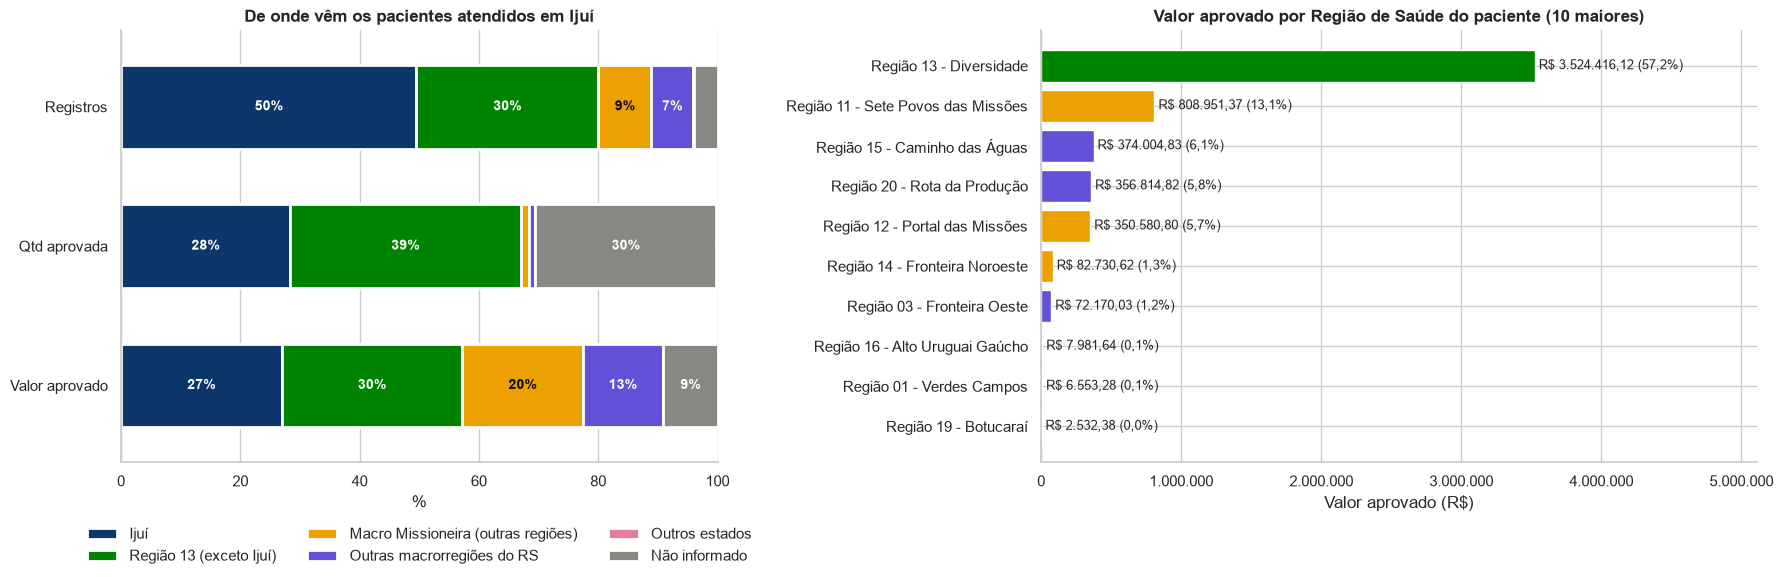

Valor aprovado por Macrorregião de Saúde do paciente:


,Registros,ValorAprovado,% Valor aprovado
MacrorregiaoPaciente,,,
MISSIONEIRA,61172,"4,766,678.91",77.40
NORTE,4058,"743,934.60",12.10
Não informado,2790,"560,014.47",9.10
CENTRO-OESTE,693,"78,884.39",1.30
METROPOLITANA,23,"2,981.86",0.00
CONE SUL,8,"1,560.85",0.00
CENTRO,6,"1,512.15",0.00
SUL,25,"1,073.27",0.00


In [27]:
# Uma cor de matiz diferente por origem (verde, amarelo e violeta validados para daltonismo, inclusive
# lado a lado no mapa); Ijuí em azul-marinho e "Não informado" em cinza. Usadas também no mapa (6.3).
CORES_ORIGEM = dict(zip(ORDEM_ORIGEM, ["#0d366b", "#008300", "#eda100", "#6250d6", "#e87ba4", COR_NEUTRA]))
TEXTO_SOBRE_COR = {"Macro Missioneira (outras regiões)": "#0b0b0b", "Outros estados": "#0b0b0b"}  # fundos claros

fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1, 1.2]})

# 1) Participação por origem regional (100% empilhado).
part = part_regional.T.rename(index={"QtdAprovada": "Qtd aprovada", "ValorAprovado": "Valor aprovado"})
part = part[[c for c in ORDEM_ORIGEM if c in part.columns]].iloc[::-1]
part.plot(kind="barh", stacked=True, ax=axes[0], color=[CORES_ORIGEM[c] for c in part.columns],
          width=0.6, edgecolor="white", linewidth=2)
for i, linha in enumerate(part.itertuples(index=False)):
    acumulado = 0
    for coluna, v in zip(part.columns, linha):
        if v >= 6:
            cor_texto = TEXTO_SOBRE_COR.get(coluna, "white")
            axes[0].text(acumulado + v / 2, i, f"{v:.0f}%", ha="center", va="center",
                         color=cor_texto, fontsize=10, fontweight="bold")
        acumulado += v
axes[0].set_xlim(0, 100)
axes[0].set_title("De onde vêm os pacientes atendidos em Ijuí")
axes[0].set_xlabel("%")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)

# 2) Regiões de Saúde de origem (valor aprovado), destacando a região de Ijuí.
regioes = (tabela[tabela["Origem"] != "Não informado"]
           .groupby("RegiaoSaudePaciente")["pa_valapr"].sum().nlargest(10).iloc[::-1])
# Cada região recebe a cor da sua origem regional (mesma legenda do gráfico da esquerda).
categoria_regiao = (tabela[tabela["Origem"] == "Outros municípios"]
                    .groupby("RegiaoSaudePaciente")["OrigemRegional"].agg(lambda s: s.mode().iloc[0]))
cores_reg = [CORES_ORIGEM["Região 13 (exceto Ijuí)"] if r == REGIAO_IJUI
             else CORES_ORIGEM.get(categoria_regiao.get(r), COR_NEUTRA) for r in regioes.index]
axes[1].barh([r.replace(" - RS", "") for r in regioes.index], regioes.values, color=cores_reg)
total_valor = tabela["pa_valapr"].sum()
for i, v in enumerate(regioes.values):
    axes[1].text(v, i, f" {br_moeda(v)} ({br_pct(v / total_valor * 100)})", va="center", fontsize=9)
axes[1].set_title("Valor aprovado por Região de Saúde do paciente (10 maiores)")
axes[1].set_xlabel("Valor aprovado (R$)")
axes[1].set_xlim(0, regioes.max() * 1.45)
formatar_eixo(axes[1], "x")

plt.tight_layout()
plt.show()

print("Valor aprovado por Macrorregião de Saúde do paciente:")
macros = (tabela.groupby("MacrorregiaoPaciente")
          .agg(Registros=("Procedimento", "size"), ValorAprovado=("pa_valapr", "sum"))
          .sort_values("ValorAprovado", ascending=False))
macros["% Valor aprovado"] = (macros["ValorAprovado"] / macros["ValorAprovado"].sum() * 100).round(1)
display(macros.head(8))

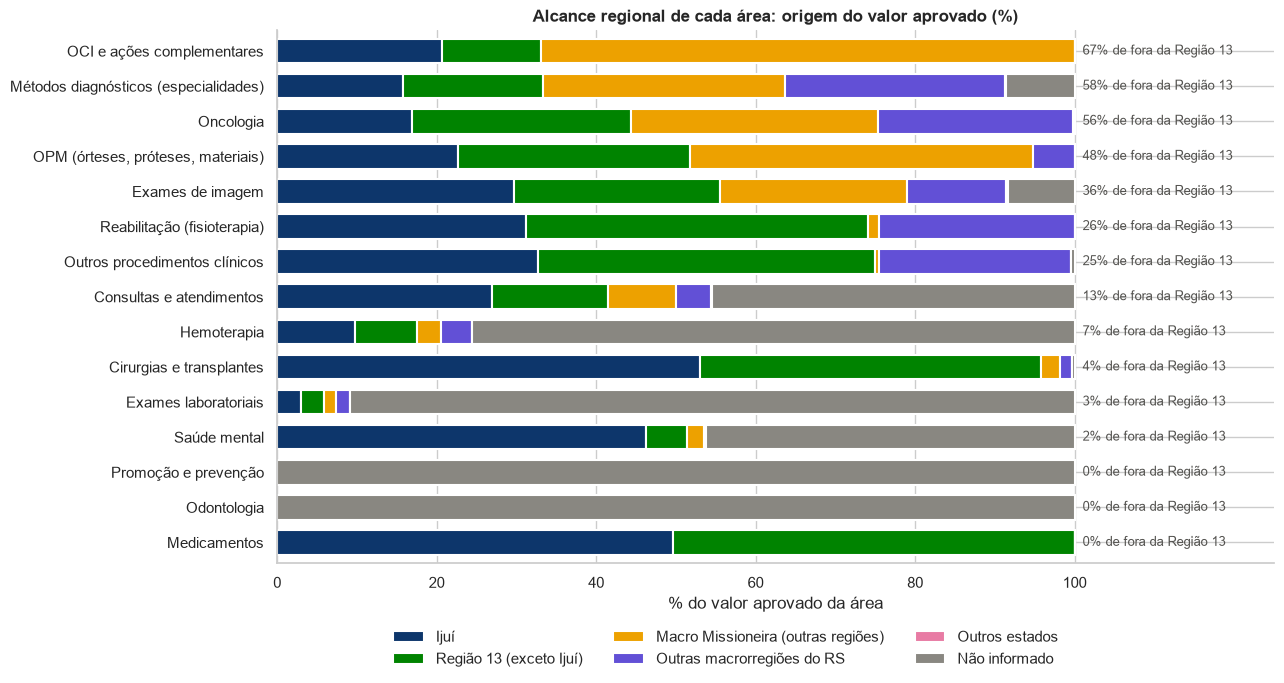

In [28]:
# Alcance regional de cada área: % do valor aprovado por origem regional.
alcance = (pd.crosstab(tabela["Area"], tabela["OrigemRegional"], values=tabela["pa_valapr"],
                       aggfunc="sum", normalize="index")
             .mul(100).fillna(0)
             .reindex(columns=[c for c in ORDEM_ORIGEM if c in tabela["OrigemRegional"].unique()]))
# Ordena pelas áreas que mais atendem de fora da Região 13.
fora_regiao = alcance.drop(columns=["Ijuí", "Região 13 (exceto Ijuí)", "Não informado"], errors="ignore").sum(axis=1)
alcance = alcance.loc[fora_regiao.sort_values().index]

fig, ax = plt.subplots(figsize=(13, 7))
alcance.plot(kind="barh", stacked=True, ax=ax, color=[CORES_ORIGEM[c] for c in alcance.columns],
             width=0.7, edgecolor="white", linewidth=1.5)
for i, v in enumerate(fora_regiao.loc[alcance.index]):
    ax.text(101, i, f"{v:.0f}% de fora da Região 13", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, 125)
ax.set_xticks(range(0, 101, 20))
ax.set_title("Alcance regional de cada área: origem do valor aprovado (%)")
ax.set_xlabel("% do valor aprovado da área")
ax.set_ylabel("")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.1), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

**Interpretação** (números de jul/2026):

- **A Região 13 é o principal público:** os moradores de Ijuí e dos outros 19 municípios da Região 13 – Diversidade respondem por cerca de **80% dos registros** e **57% do valor aprovado**.
- **Ijuí atende muito além da sua região:** cerca de **34% do valor aprovado** (R$ 2,1 milhões) é de pacientes de **outras regiões de saúde**:
  - cerca de 20% vem do restante da **Macrorregião Missioneira**, principalmente a Região 11 – Sete Povos das Missões e a Região 12 – Portal das Missões;
  - cerca de 13% vem de **outras macrorregiões**, sobretudo a Macro Norte (Regiões 15 – Caminho das Águas e 20 – Rota da Produção).
- **Medicamentos × oncologia:** a dispensação de medicamentos pela 17ª CRS atende **só a Região 13**, porque é a área de abrangência da coordenadoria. Já a **oncologia** tem alcance **macrorregional**: mais da metade do seu valor vem de fora da Região 13, inclusive de outras macrorregiões.
- **Outros serviços de alcance regional:** **órteses e próteses** (aparelhos auditivos) e **exames de imagem** também atendem muito fora da Região 13.

**Para a gestão:** os serviços de alta complexidade de Ijuí funcionam como **referência macrorregional**. Isso deve estar refletido na pactuação (PPI) e nas negociações com as regiões de origem, porque a demanda dessas regiões ocupa capacidade instalada e orçamento do município. O gráfico de alcance mostra **quais serviços** sustentam essa referência e onde a dependência de pacientes de fora é maior.

### 6.3 Mapa dos fluxos de pacientes

**Pergunta:** geograficamente, até onde chega o atendimento prestado em Ijuí?

O mapa é desenhado só com Matplotlib, **sem shapefile**:

- os **municípios do RS** (coordenadas de `tb_municip`) aparecem como pontos de fundo e formam o contorno do estado; os da **Região 13** ficam em azul claro;
- cada **bolha** é um município de origem dos pacientes: a **área** é proporcional ao valor aprovado e a **cor** segue a origem regional da Seção 6.2;
- as **linhas** ligam cada município a Ijuí, com espessura proporcional ao valor aprovado.

O painel da direita repete o mapa só para a **oncologia**, a área de maior alcance regional. Registros sem município válido (BPA consolidado) e de outros estados não aparecem no mapa.

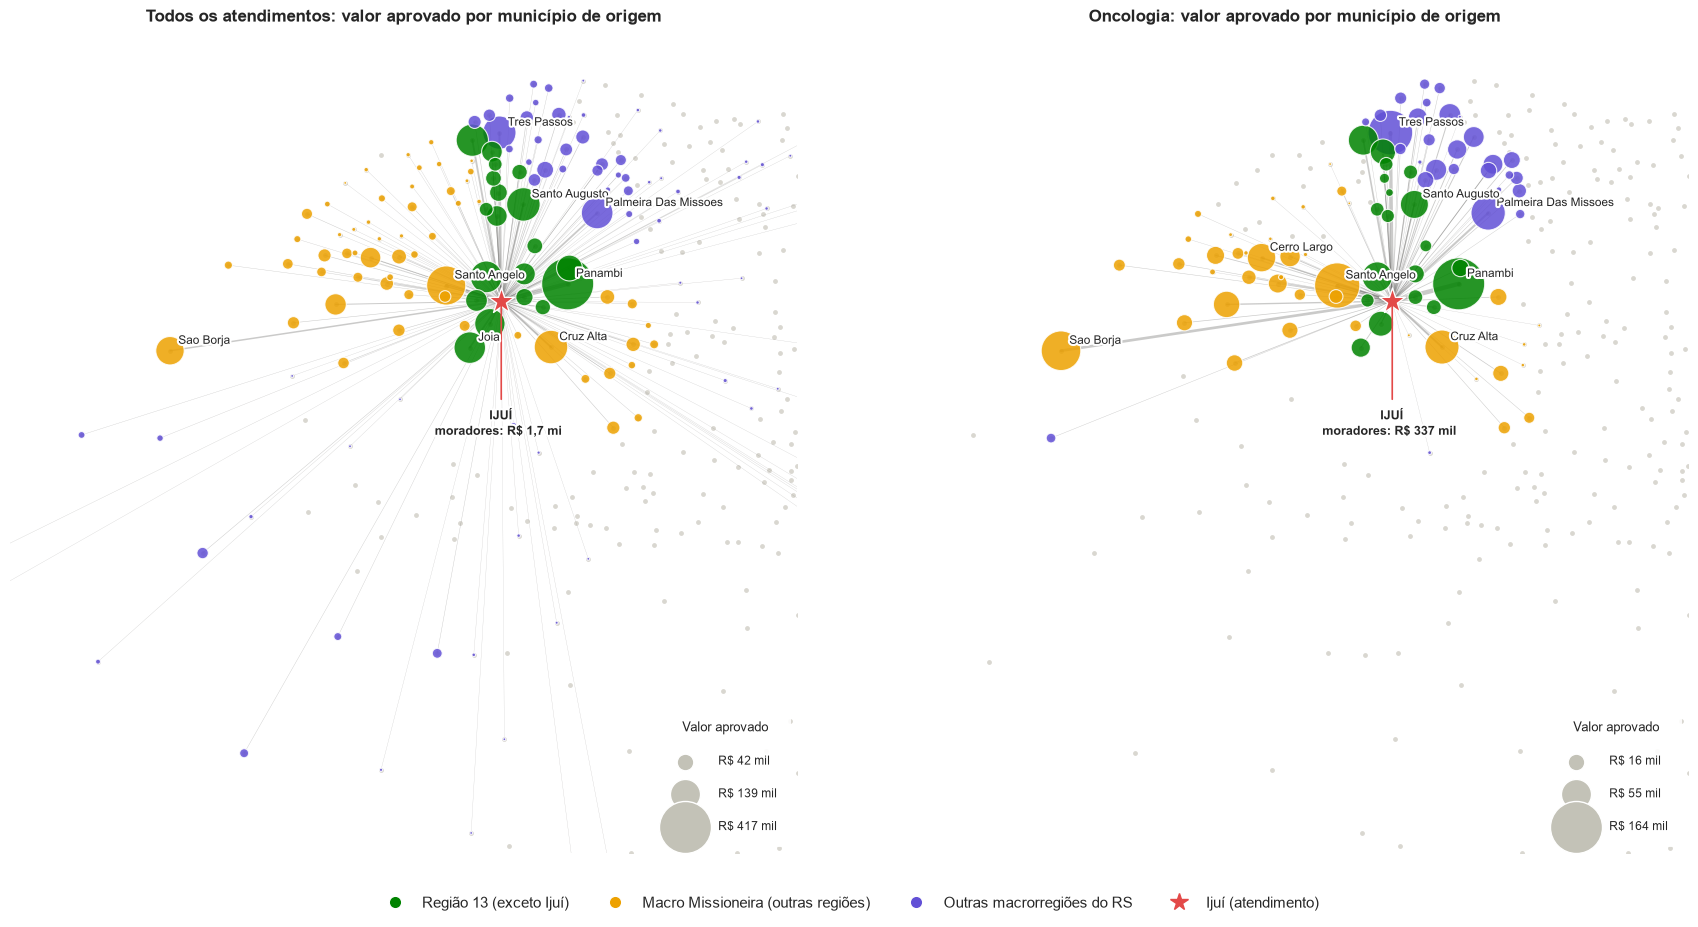

Municípios de origem: 163 (todos) | 89 (oncologia)
Fora do quadro do mapa (linhas cortadas na borda): 17 municípios, 0,2% do valor aprovado
10 municípios de origem com maior valor aprovado (exceto Ijuí):


,MunicipioPaciente,OrigemRegional,Registros,ValorAprovado,% do valor
93,Panambi,Região 13 (exceto Ijuí),3127,"416,571.29",6.80
123,Santo Angelo,Macro Missioneira (outras regiões),956,"235,027.22",3.80
42,Cruz Alta,Macro Missioneira (outras regiões),975,"172,295.75",2.80
126,Santo Augusto,Região 13 (exceto Ijuí),1735,"171,641.81",2.80
152,Tres Passos,Outras macrorregiões do RS,830,"168,880.19",2.70
41,Crissiumal,Região 13 (exceto Ijuí),1839,"159,601.39",2.60
29,Catuipe,Região 13 (exceto Ijuí),1770,"154,540.50",2.50
91,Palmeira Das Missoes,Outras macrorregiões do RS,898,"153,301.51",2.50
75,Joia,Região 13 (exceto Ijuí),2559,"152,014.64",2.50
8,Augusto Pestana,Região 13 (exceto Ijuí),1648,"140,702.18",2.30


In [29]:
def coordenada(serie):
    """Converte coordenadas gravadas com vírgula decimal ('-28,38') em número."""
    return pd.to_numeric(serie.astype(str).str.strip().str.replace(",", ".", regex=False), errors="coerce")


mapa_rs = municipios_rs.assign(lat=coordenada(municipios_rs["nu_latitud"]),
                               lon=coordenada(municipios_rs["nu_longit"])).dropna(subset=["lat", "lon"])
mapa_rs["co_municip"] = mapa_rs["co_municip"].astype(str).str.strip()
mapa_rs["co_regsaud"] = mapa_rs["co_regsaud"].astype(str).str.strip()
ijui = mapa_rs.loc[mapa_rs["co_municip"] == "431020"].iloc[0]
COD_REGIAO_IJUI = ijui["co_regsaud"]

tabela["LatPaciente"] = coordenada(tabela["LatPaciente"])
tabela["LonPaciente"] = coordenada(tabela["LonPaciente"])
tabela["CodMunicipioPaciente"] = tabela["CodMunicipioPaciente"].astype(str).str.strip()


def fluxos_por_municipio(df):
    """Valor aprovado e registros por município de origem (somente RS, com coordenadas)."""
    no_rs = df["UFPaciente"].astype(str).str.strip().eq("RS")
    return (df[no_rs & df["LatPaciente"].notna() & (df["Origem"] != "Não informado")]
            .groupby(["CodMunicipioPaciente", "MunicipioPaciente", "OrigemRegional"], as_index=False)
            .agg(Registros=("Procedimento", "size"), ValorAprovado=("pa_valapr", "sum"),
                 lat=("LatPaciente", "first"), lon=("LonPaciente", "first"))
            .sort_values("ValorAprovado", ascending=False))


import matplotlib.patheffects as efeitos
from matplotlib.lines import Line2D

TAMANHO_MAX = 1400   # área (pt²) da maior bolha


def br_mil(v):
    """Valor resumido: R$ 42 mil, R$ 1,7 mi."""
    return f"R$ {br_num(v / 1e6, 1)} mi" if v >= 1e6 else f"R$ {br_num(v / 1e3)} mil"


def desenhar_mapa(ax, fluxos, titulo, limites, n_rotulos=8):
    # Ijuí é o destino: marcado com estrela; as bolhas mostram só os municípios de ORIGEM de fora.
    origem = fluxos[fluxos["OrigemRegional"] != "Ijuí"]
    valor_ijui = fluxos.loc[fluxos["OrigemRegional"] == "Ijuí", "ValorAprovado"].sum()
    escala_max = origem["ValorAprovado"].max()
    tamanho = lambda v: TAMANHO_MAX * v / escala_max + 4

    # Fundo: todos os municípios do RS (formam o contorno do estado).
    ax.scatter(mapa_rs["lon"], mapa_rs["lat"], s=6, color="#d9d7d0", zorder=1)

    # Linhas de fluxo até Ijuí (espessura proporcional ao valor).
    for _, f in origem.iterrows():
        ax.plot([f["lon"], ijui["lon"]], [f["lat"], ijui["lat"]], color="#52514e",
                linewidth=0.2 + 3 * f["ValorAprovado"] / escala_max, alpha=0.3, zorder=2)

    # Bolhas: área proporcional ao valor aprovado (maiores primeiro, para as menores ficarem visíveis).
    ax.scatter(origem["lon"], origem["lat"], s=tamanho(origem["ValorAprovado"]),
               c=[CORES_ORIGEM[o] for o in origem["OrigemRegional"]], alpha=0.85,
               edgecolor="white", linewidth=0.8, zorder=3)
    ax.scatter(ijui["lon"], ijui["lat"], marker="*", s=380, color="#e34948", edgecolor="white",
               linewidth=1, zorder=5)
    halo = [efeitos.withStroke(linewidth=3, foreground="white")]
    ax.annotate(f"IJUÍ\nmoradores: {br_mil(valor_ijui)}", (ijui["lon"], ijui["lat"]),
                xytext=(0, -75), textcoords="offset points", ha="center", va="top", fontsize=9,
                fontweight="bold", path_effects=halo, zorder=6,
                arrowprops=dict(arrowstyle="-", color="#e34948", linewidth=1.2))

    # Rótulos dos maiores municípios de origem, pulando os muito próximos de um rótulo já colocado.
    ocupados = [(ijui["lon"], ijui["lat"])]
    for _, f in origem.iterrows():
        if len(ocupados) > n_rotulos:
            break
        if all(np.hypot(f["lon"] - x, f["lat"] - y) > 0.3 for x, y in ocupados):
            ax.annotate(f["MunicipioPaciente"], (f["lon"], f["lat"]), xytext=(6, 5), textcoords="offset points",
                        fontsize=8.5, path_effects=halo, zorder=6)
            ocupados.append((f["lon"], f["lat"]))

    # Legenda de tamanho: três valores de referência.
    referencias = [escala_max / 10, escala_max / 3, escala_max]
    alcas = [ax.scatter([], [], s=tamanho(v), color="#c3c2b7", edgecolor="white") for v in referencias]
    ax.legend(alcas, [br_mil(v) for v in referencias], title="Valor aprovado",
              loc="lower right", frameon=True, framealpha=0.9, edgecolor="none",
              labelspacing=1.8, borderpad=1.2, handletextpad=1.8, fontsize=8.5, title_fontsize=9)

    ax.set_aspect(1 / np.cos(np.radians(ijui["lat"])))   # corrige a proporção lon x lat
    ax.set_xlim(limites[0], limites[1])
    ax.set_ylim(limites[2], limites[3])
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for lado in ax.spines.values():
        lado.set_visible(False)
    ax.set_title(titulo)


fluxos_total = fluxos_por_municipio(tabela)
fluxos_onco = fluxos_por_municipio(tabela[tabela["Area"] == "Oncologia"])

# Enquadramento: área dos municípios que somam 97% do valor de fora de Ijuí (mesmo quadro nos dois mapas).
de_fora = fluxos_total[fluxos_total["OrigemRegional"] != "Ijuí"]
acumulado = de_fora["ValorAprovado"].cumsum() / de_fora["ValorAprovado"].sum()
nucleo = de_fora[acumulado.shift(fill_value=0) < 0.97]
limites = (nucleo["lon"].min() - 0.45, nucleo["lon"].max() + 0.9,
           nucleo["lat"].min() - 0.55, nucleo["lat"].max() + 0.3)
fora_do_quadro = de_fora[~de_fora["lon"].between(limites[0], limites[1]) | ~de_fora["lat"].between(limites[2], limites[3])]

fig, axes = plt.subplots(1, 2, figsize=(18, 9))
desenhar_mapa(axes[0], fluxos_total, "Todos os atendimentos: valor aprovado por município de origem", limites)
desenhar_mapa(axes[1], fluxos_onco, "Oncologia: valor aprovado por município de origem", limites)

# Legenda de cores (origem regional), comum aos dois mapas.
cores_leg = [Line2D([], [], marker="o", linestyle="", markersize=9, markerfacecolor=CORES_ORIGEM[o],
                    markeredgecolor="white", label=o)
             for o in ORDEM_ORIGEM if o != "Ijuí" and o in fluxos_total["OrigemRegional"].unique()]
cores_leg.append(Line2D([], [], marker="*", linestyle="", markersize=13, color="#e34948", label="Ijuí (atendimento)"))
fig.legend(handles=cores_leg, loc="lower center", ncol=len(cores_leg), frameon=False, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

print(f"Municípios de origem: {len(fluxos_total)} (todos) | {len(fluxos_onco)} (oncologia)")
print(f"Fora do quadro do mapa (linhas cortadas na borda): {len(fora_do_quadro)} municípios, "
      f"{br_pct(fora_do_quadro['ValorAprovado'].sum() / tabela['pa_valapr'].sum() * 100)} do valor aprovado")
print("10 municípios de origem com maior valor aprovado (exceto Ijuí):")
top_fluxos = fluxos_total[fluxos_total["OrigemRegional"] != "Ijuí"].head(10).copy()
top_fluxos["% do valor"] = (top_fluxos["ValorAprovado"] / tabela["pa_valapr"].sum() * 100).round(1)
display(top_fluxos[["MunicipioPaciente", "OrigemRegional", "Registros", "ValorAprovado", "% do valor"]])

**Interpretação** (jul/2026):

- **Alcance:** pacientes de **cerca de 160 municípios do RS** foram atendidos em Ijuí, quase todos no **norte e noroeste do estado** (Macrorregiões Missioneira e Norte). Municípios do leste e do sul praticamente não aparecem; provavelmente são atendidos por outros polos. Os municípios fora do quadro do mapa somam menos de 1% do valor.
- **Maiores origens:** **Panambi**, da própria Região 13, é a maior origem de fora (cerca de R$ 417 mil, quase 7% do valor do município). Em seguida vêm **Santo Ângelo** e **Cruz Alta** (outras regiões da Macro Missioneira) e **Três Passos** e **Palmeira das Missões** (Macro Norte).
- **Oncologia:** atende cerca de **90 municípios**, numa área maior que a da Região 13. As bolhas grandes de **São Borja** (mais de 200 km em linha reta), **Santo Ângelo**, **Três Passos** e **Palmeira das Missões** mostram o HCI como **referência em oncologia para toda a metade norte/noroeste do RS**. No mapa geral, a oncologia ganha destaque porque cada paciente representa um valor alto.

**Para a gestão:** o mapa traduz em geografia o que a Seção 6.2 mostrou em números. Ijuí sustenta uma rede de atendimento que vai muito além dos seus limites e da sua Região de Saúde. Esse é o argumento visual mais direto para discutir **pactuação, cofinanciamento e transporte sanitário** com os municípios e regiões de origem.

---
## 7. Recursos financeiros

### 7.1 Valores aprovados × produzidos

**Perguntas:** qual é o total aprovado pelo SUS para Ijuí frente ao produzido? Qual é a diferença?

,Indicador,Valor
0,Valor produzido,"R$ 6.272.060,94"
1,Valor aprovado,"R$ 6.158.024,69"
2,Diferença (produzido − aprovado),"R$ 114.036,25"
3,% aprovado,"98,2%"


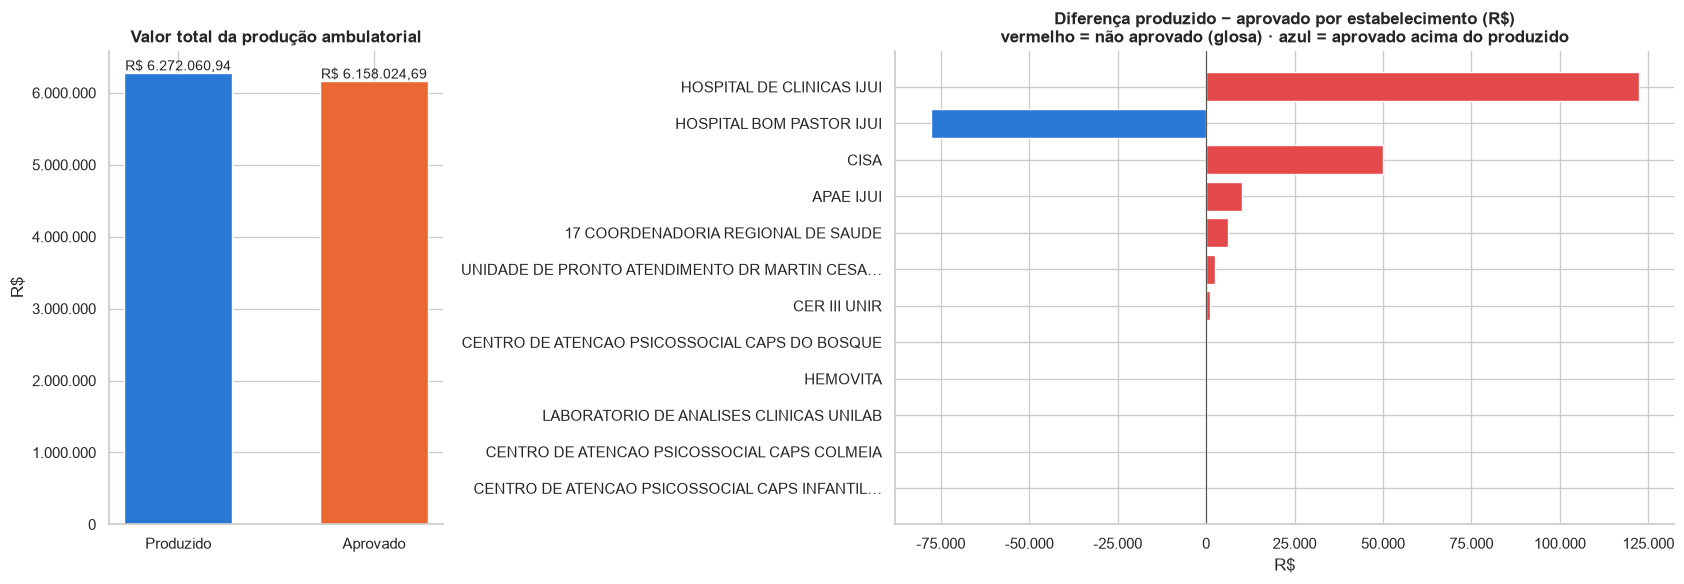

In [30]:
valor_prod, valor_aprov = tabela["pa_valpro"].sum(), tabela["pa_valapr"].sum()
financeiro = pd.DataFrame({
    "Indicador": ["Valor produzido", "Valor aprovado", "Diferença (produzido − aprovado)", "% aprovado"],
    "Valor": [br_moeda(valor_prod), br_moeda(valor_aprov), br_moeda(valor_prod - valor_aprov),
              br_pct(valor_aprov / valor_prod * 100)],
})
display(financeiro)

# Diferença por estabelecimento: positivo = glosa (aprovado < produzido); negativo = aprovado acima do produzido.
dif = ranking.assign(Diferenca=ranking["ValorProduzido"] - ranking["ValorAprovado"])
dif = dif.reindex(dif["Diferenca"].abs().sort_values(ascending=False).index).head(12).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [0.6, 1.4]})

axes[0].bar(["Produzido", "Aprovado"], [valor_prod, valor_aprov], color=[COR_PRODUZIDO, COR_APROVADO], width=0.55)
for i, v in enumerate([valor_prod, valor_aprov]):
    axes[0].text(i, v, br_moeda(v), ha="center", va="bottom", fontsize=10)
axes[0].set_title("Valor total da produção ambulatorial")
axes[0].set_ylabel("R$")
formatar_eixo(axes[0], "y")

cores = ["#e34948" if d > 0 else COR_PRODUZIDO for d in dif["Diferenca"]]
axes[1].barh(dif["Estabelecimento"].map(rotulo_curto), dif["Diferenca"], color=cores)
axes[1].axvline(0, color="#52514e", linewidth=0.8)
axes[1].set_title("Diferença produzido − aprovado por estabelecimento (R$)\n"
                  "vermelho = não aprovado (glosa) · azul = aprovado acima do produzido")
axes[1].set_xlabel("R$")
formatar_eixo(axes[1], "x")

plt.tight_layout()
plt.show()

**Interpretação:** em jul/2026, foram aprovados cerca de **98% do valor** produzido, contra cerca de **79% da quantidade** (Seção 4.2). As glosas recaem sobretudo sobre procedimentos de **baixo valor unitário** e alto volume (medicamentos por unidade, exames, sessões). As barras azuis (aprovado acima do produzido) também merecem atenção, em especial o **Hospital Bom Pastor**, com cerca de R$ 78 mil aprovados acima do apresentado. Isso pode decorrer de incentivos ou complementos aplicados no processamento, ou de diferença de tabela entre apresentação e aprovação, e deve ser conferido junto ao setor de faturamento.

### 7.2 Gasto médio por procedimento

**Pergunta:** quanto custa, em média, cada procedimento aprovado, e como isso evolui?

**Gasto médio** = valor aprovado ÷ quantidade aprovada.

Gasto médio geral por procedimento aprovado: R$ 16,89


,MAExt,QtdAprovada,ValorAprovado,GastoMedio
0,Jul-2026,"364,679.00","6,158,024.69",16.89


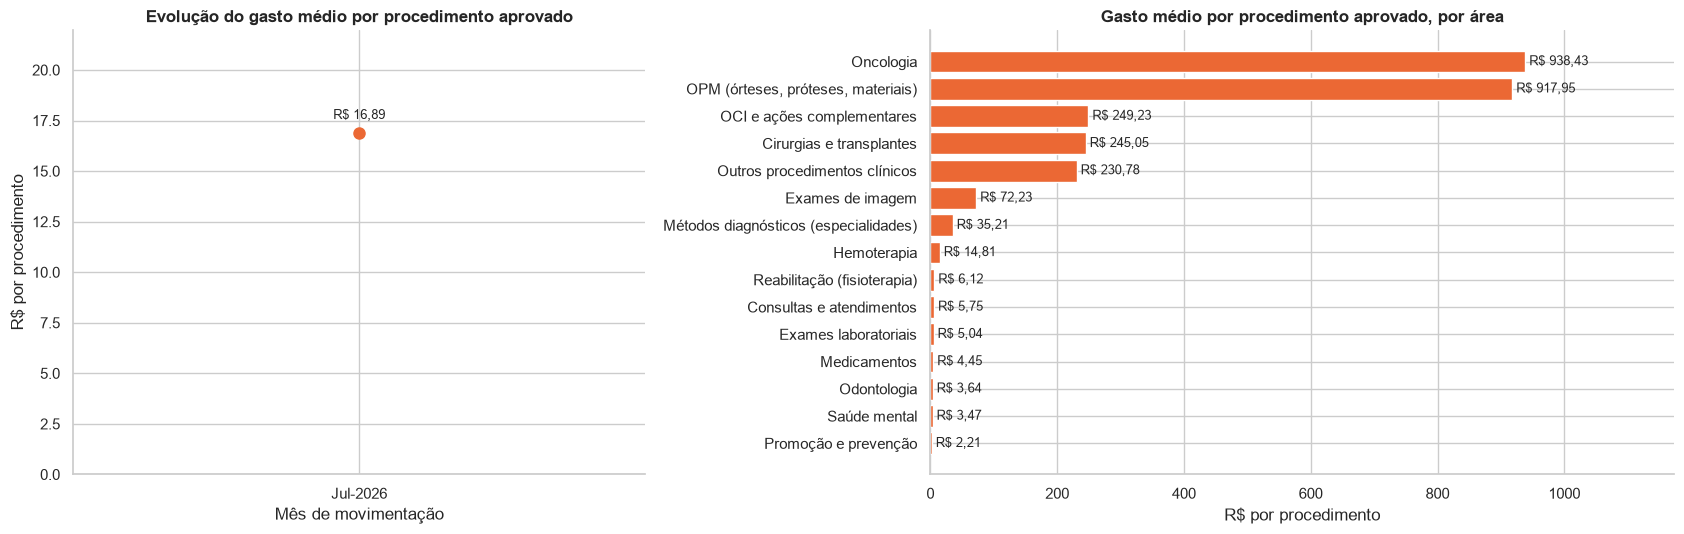

In [31]:
areas["GastoMedio"] = areas["ValorAprovado"] / areas["QtdAprovada"].where(areas["QtdAprovada"] > 0)
mensal["GastoMedio"] = mensal["ValorAprovado"] / mensal["QtdAprovada"].where(mensal["QtdAprovada"] > 0)
print(f"Gasto médio geral por procedimento aprovado: {br_moeda(valor_aprov / tabela['pa_qtdapr'].sum())}")
display(mensal[["MAExt", "QtdAprovada", "ValorAprovado", "GastoMedio"]])

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1, 1.3]})

axes[0].plot(mensal["MAExt"], mensal["GastoMedio"], marker="o", linewidth=2, markersize=8, color=COR_APROVADO)
for x, y in zip(mensal["MAExt"], mensal["GastoMedio"]):
    axes[0].annotate(br_moeda(y), (x, y), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9)
axes[0].set_title("Evolução do gasto médio por procedimento aprovado")
axes[0].set_xlabel("Mês de movimentação")
axes[0].set_ylabel("R$ por procedimento")
axes[0].set_ylim(bottom=0, top=mensal["GastoMedio"].max() * 1.3)

g = areas.dropna(subset=["GastoMedio"]).sort_values("GastoMedio")
axes[1].barh(g["Area"], g["GastoMedio"], color=COR_APROVADO)
for i, v in enumerate(g["GastoMedio"]):
    axes[1].text(v, i, " " + br_moeda(v), va="center", fontsize=9)
axes[1].set_title("Gasto médio por procedimento aprovado, por área")
axes[1].set_xlabel("R$ por procedimento")
axes[1].set_xlim(0, g["GastoMedio"].max() * 1.25)

plt.tight_layout()
plt.show()

**Interpretação:** o gasto médio geral é baixo porque é "diluído" pelos procedimentos de alto volume e baixo custo. Por área, as diferenças são de **ordens de grandeza**: um procedimento de oncologia (quimioterapia, por exemplo) pode custar centenas ou milhares de reais, enquanto um exame laboratorial custa poucos reais. A **evolução** do gasto médio só poderá ser avaliada com mais meses na base. Uma alta no gasto médio pode indicar mudança no perfil (mais alta complexidade), e não necessariamente aumento de preço.

---
## 8. Foco em áreas críticas

### 8.1 Oncologia: quimioterapia e radioterapia (aprovados × produzidos)

Classificação pelo código SIGTAP: subgrupo `0304` (tratamento em oncologia), com `030401` = radioterapia e `030402`–`030407` = quimioterapia, mais `0416` (cirurgia oncológica).

,TipoOnco,Registros,QtdProduzida,QtdAprovada,ValorProduzido,ValorAprovado,TaxaAprovQtd_%,TaxaAprovValor_%,APACs distintas (≈ pacientes)
1,Quimioterapia,1990,"1,845.00","1,844.00","1,142,463.37","1,142,383.62",99.90,100.00,1990
2,Radioterapia,144,169.00,168.00,"802,672.80","798,931.20",99.40,99.50,144
0,"Outros (suporte, intercorrências, iodoterapia)",121,120.00,120.00,"59,407.90","59,407.90",100.00,100.00,2


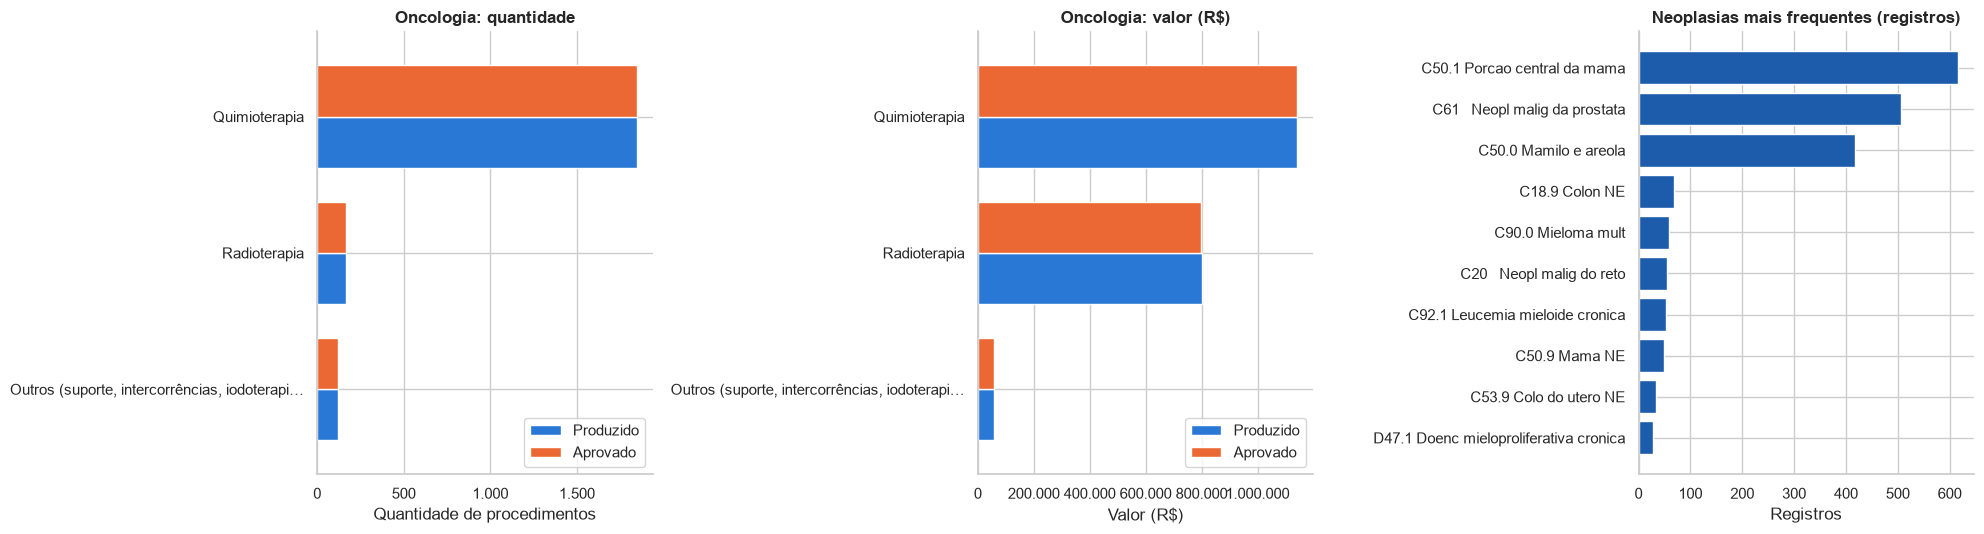

Origem dos pacientes de oncologia (% dos registros):


,%
Origem,
Outros municípios,80.10
Ijuí,19.90


In [32]:
onco = tabela[tabela["Area"] == "Oncologia"].copy()
# Pelo código SIGTAP: 030401 radioterapia (inclui braquiterapia/betaterapia); 030402-030407 quimioterapia;
# 0416 cirurgia oncológica; o restante (030408 suporte, 030410 intercorrências, iodoterapia) fica em "Outros".
co6 = onco["CodProcedimento"].str[:6]
onco["TipoOnco"] = np.select(
    [co6.eq("030401"),
     co6.isin(["030402", "030403", "030404", "030405", "030406", "030407"]),
     onco["CodProcedimento"].str[:4].eq("0416")],
    ["Radioterapia", "Quimioterapia", "Cirurgia oncológica"],
    default="Outros (suporte, intercorrências, iodoterapia)")

resumo_onco = resumo_producao(onco, "TipoOnco").sort_values("ValorAprovado", ascending=False)

# Pacientes em tratamento: o arquivo não identifica o paciente, mas cada APAC (procedimento principal)
# corresponde a um paciente em tratamento naquele mês. APACs distintas ≈ pacientes-mês.
apac_principal = onco[onco["Instrumento"].astype(str).str.strip().eq("P")
                      & onco["NumAutorizacao"].astype(str).str.strip().ne("")]
resumo_onco["APACs distintas (≈ pacientes)"] = resumo_onco["TipoOnco"].map(
    apac_principal.groupby("TipoOnco")["NumAutorizacao"].nunique()).fillna(0).astype(int)
display(resumo_onco)

if onco.empty:
    print("Nenhum registro de oncologia encontrado.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
    barras_produzido_aprovado(resumo_onco, "TipoOnco", axes[0], "Qtd", "Oncologia: quantidade")
    barras_produzido_aprovado(resumo_onco, "TipoOnco", axes[1], "Valor", "Oncologia: valor (R$)")

    top_onco = (onco[onco["CID"] != "Não informado"]["Diagnostico"].value_counts().head(10).iloc[::-1])
    axes[2].barh(top_onco.index.map(rotulo_curto), top_onco.values, color=COR_SERIE)
    axes[2].set_title("Neoplasias mais frequentes (registros)")
    axes[2].set_xlabel("Registros")
    plt.tight_layout()
    plt.show()

    print("Origem dos pacientes de oncologia (% dos registros):")
    display(onco["Origem"].value_counts(normalize=True).mul(100).round(1).to_frame("%"))

**Interpretação:** em jul/2026, toda a oncologia ambulatorial de Ijuí está no **Hospital de Clínicas (HCI)**, com cerca de **R$ 2,0 milhões aprovados**, um terço de todo o valor do município:

- **Quimioterapia:** cerca de 1.990 APACs, ou seja, cerca de 1.990 pacientes em tratamento no mês, e R$ 1,14 milhão.
- **Radioterapia:** cerca de 144 APACs e R$ 0,80 milhão. O custo por paciente é bem maior que o da quimioterapia.

A aprovação é praticamente **total** (cerca de 99,9%) porque a APAC é **autorizada antes** do tratamento. Assim, nessa área o risco para a gestão não é a glosa, mas a **capacidade e o financiamento**: cerca de **80% dos pacientes vêm de outros municípios**, o que confirma o HCI como **referência regional em oncologia** e reforça a necessidade de pactuação regional.

**Observação:** as APACs distintas são uma **aproximação** do número de pacientes (uma APAC por paciente em tratamento no mês). O arquivo público não identifica o paciente.

### 8.2 Saúde mental: atendimentos psiquiátricos e psicológicos

,Profissional,Registros,QtdProduzida,QtdAprovada,ValorProduzido,ValorAprovado,TaxaAprovQtd_%,TaxaAprovValor_%
0,Equipe multiprofissional (CAPS),5552,"11,769.00","8,596.00","9,747.92","9,747.92",73.00,100.00
1,Psicologia,4121,"4,969.00","4,327.00","30,469.68","30,003.48",87.10,98.50
2,Psiquiatria,566,"1,389.00","1,370.00","9,820.00","9,810.00",98.60,99.90


,Estabelecimento,Registros,QtdProduzida,QtdAprovada,ValorProduzido,ValorAprovado,TaxaAprovQtd_%,TaxaAprovValor_%
2,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,4326,"8,005.00","5,184.00","4,624.20","4,624.20",64.80,100.00
3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS INFANTIL CARAMELO,2825,"4,215.00","3,447.00","4,002.10","4,002.10",81.80,100.00
1,CENTRO DE ATENCAO PSICOSSOCIAL CAPS COLMEIA,1043,"3,425.00","3,255.00","9,075.42","9,075.42",95.00,100.00
0,APAE IJUI,1242,"1,242.00","1,242.00","21,946.14","21,946.14",100.00,100.00
6,CISA,81,510.00,510.00,"5,100.00","5,100.00",100.00,100.00
5,CER III UNIR,422,422.00,422.00,"3,464.64","3,464.64",100.00,100.00
7,HOSPITAL DE CLINICAS IJUI,270,270.00,195.00,"1,730.60","1,254.40",72.20,72.50
4,CENTRO DE REFERENCIA REGIONAL EM SAUDE DO TRABALHADOR,30,38.00,38.00,94.50,94.50,100.00,100.00


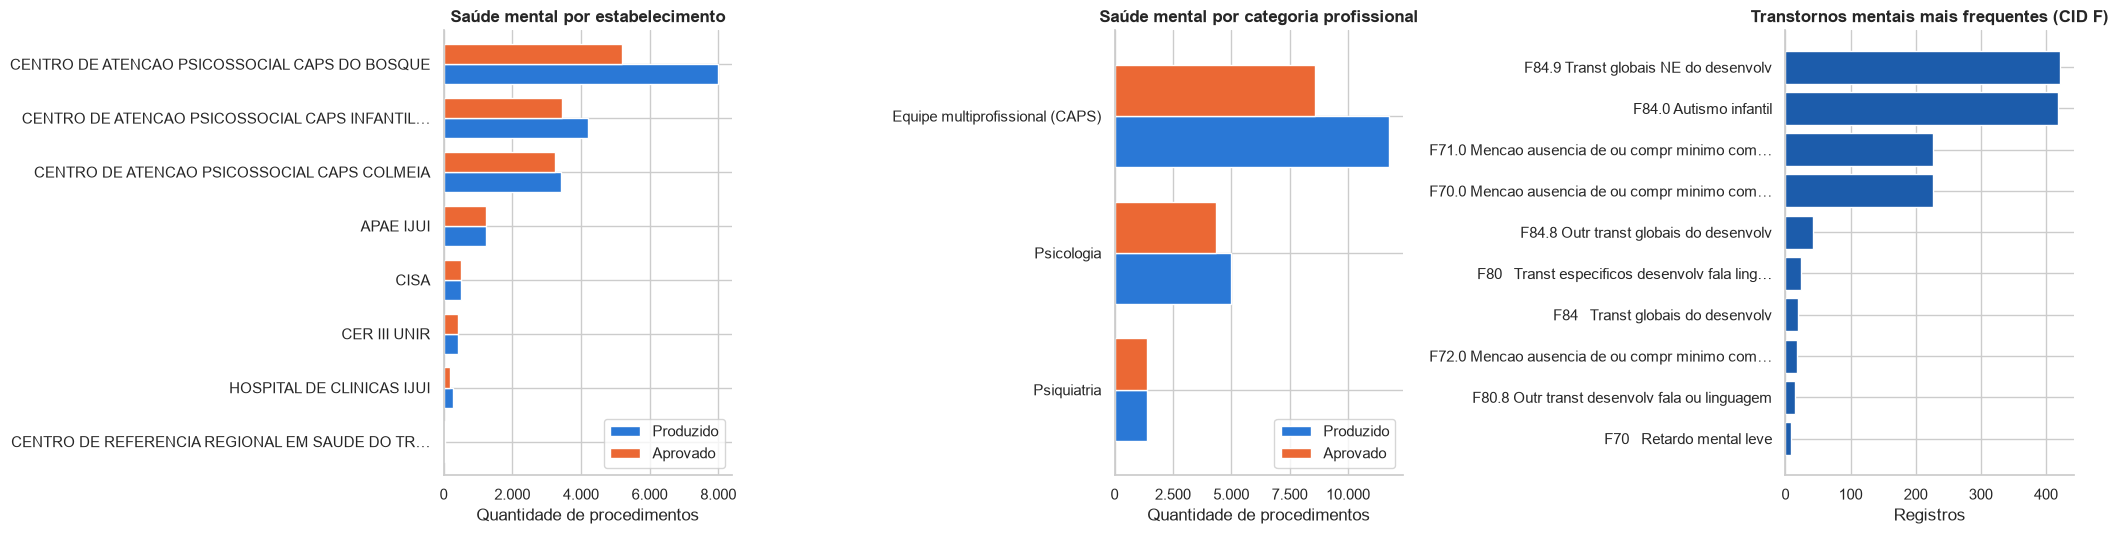

In [33]:
mental = tabela[tabela["Area"] == "Saúde mental"].copy()
ocup_mental = normalizar(mental["Ocupacao"])
mental["Profissional"] = np.select(
    [ocup_mental.str.contains("PSIQUIATRA"), ocup_mental.str.contains("PSICOLOG")],
    ["Psiquiatria", "Psicologia"], default="Equipe multiprofissional (CAPS)")

por_estab_mental = resumo_producao(mental, "Estabelecimento").sort_values("QtdAprovada", ascending=False)
por_prof_mental = resumo_producao(mental, "Profissional").sort_values("QtdAprovada", ascending=False)
display(por_prof_mental)
display(por_estab_mental.head(10))

if mental.empty:
    print("Nenhum registro de saúde mental encontrado.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
    barras_produzido_aprovado(por_estab_mental.head(8), "Estabelecimento", axes[0],
                              titulo="Saúde mental por estabelecimento")
    barras_produzido_aprovado(por_prof_mental, "Profissional", axes[1],
                              titulo="Saúde mental por categoria profissional")

    cid_f = mental[mental["CID"].str.startswith("F")]["Diagnostico"].value_counts().head(10).iloc[::-1]
    axes[2].barh(cid_f.index.map(rotulo_curto), cid_f.values, color=COR_SERIE)
    axes[2].set_title("Transtornos mentais mais frequentes (CID F)")
    axes[2].set_xlabel("Registros")
    plt.tight_layout()
    plt.show()

**Interpretação:** a rede de saúde mental de Ijuí é sustentada pelos **três CAPS** (Bosque, Colmeia e Infantil Caramelo), com cerca de **80% dos registros** da área. A **equipe multiprofissional** (acolhimento, grupos, oficinas) responde pela maior parte da quantidade aprovada. Os atendimentos por **psicólogos** (CAPS, APAE, hospitais) e **psiquiatras** somam cerca de 46% dos registros, mas só cerca de 40% da quantidade. O **CAPS do Bosque** teve cerca de **65%** da quantidade aprovada em jul/2026, a menor taxa da rede. Como os procedimentos de CAPS têm valor unitário baixo, a perda financeira é pequena, mas a produção não reconhecida **subestima a atividade** do serviço nos indicadores oficiais. Vale revisar o registro (RAAS) com a equipe. O gráfico de CID F mostra só a parte dos atendimentos que traz diagnóstico (Seção 1.3), então deve ser lido como indicativo do perfil da demanda.

### 8.3 Atenção básica: UBS e acompanhamento de doenças crônicas

**Pergunta:** as UBS/ESF de Ijuí aparecem na produção ambulatorial do SIA?

A lista de UBS/ESF vem do **cadastro de estabelecimentos (CNES / `cadgerrs`)**, filtrado por Ijuí (`codufmun = '431020'`). Em seguida, verificamos se cada uma tem algum registro no PARS.

UBS/ESF cadastradas em Ijuí: 20 | com produção no SIA: 0


,CNES,Estabelecimento,Registros no SIA
0,6820271,ESTRATEGIA SAUDE DA FAMILIA ASSIS BRASIL ESF 12,0
1,9856412,ESTRATEGIA SAUDE DA FAMILIA BOA VISTA ESF 17,0
2,7417470,ESTRATEGIA SAUDE DA FAMILIA CENTRO ESF 18 19,0
3,2260948,ESTRATEGIA SAUDE DA FAMILIA CENTRO SOCIAL URBANO ESF 7 8,0
4,7267924,ESTRATEGIA SAUDE DA FAMILIA GETULIO VARGAS ESF 14 ESF 15,0
5,2260956,ESTRATEGIA SAUDE DA FAMILIA GLORIA ESF 3,0
6,2260131,ESTRATEGIA SAUDE DA FAMILIA HERVAL ESF 4,0
7,9855416,ESTRATEGIA SAUDE DA FAMILIA JARDIM ESF 16,0
8,2265796,ESTRATEGIA SAUDE DA FAMILIA MEIO RURAL ESF 9 10,0
9,2260840,ESTRATEGIA SAUDE DA FAMILIA MUNDSTOCK ESF 13,0


Registros do SIA com característica de atenção básica: 297 (0,43% do total)
Onde estão esses registros (nenhum é de UBS):


,Estabelecimento,TipoEstabelecimento,Registros,QtdProduzida,QtdAprovada,ValorProduzido,ValorAprovado,TaxaAprovQtd_%,TaxaAprovValor_%
1,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,CAPS,92,313.00,313.00,0.00,0.00,100.00,NaN
0,CENTRO DE ATENCAO PSICOSSOCIAL CAPS COLMEIA,CAPS,72,320.00,320.00,0.00,0.00,100.00,NaN
7,UNIDADE DE PRONTO ATENDIMENTO DR MARTIN CESAR AGNOLETTO,Pronto atendimento (UPA),46,79.00,79.00,0.00,0.00,100.00,NaN
6,SAMU 192 SA16 IJUI,Unidade móvel de urgência (SAMU),44,57.00,57.00,0.00,0.00,100.00,NaN
2,CENTRO DE ATENCAO PSICOSSOCIAL CAPS INFANTIL CARAMELO,CAPS,35,167.00,167.00,0.00,0.00,100.00,NaN
4,CISA,Apoio diagnóstico e terapia (SADT),5,"2,390.00","2,390.00",0.00,0.00,100.00,NaN
5,HOSPITAL DE CLINICAS IJUI,Hospital geral,2,58.00,58.00,0.00,0.00,100.00,NaN
3,CENTRO DE REFERENCIA REGIONAL EM SAUDE DO TRABALHADOR,Clínica / centro de especialidade,1,1.00,1.00,0.00,0.00,100.00,NaN


Registros com CID de hipertensão ou diabetes, por tipo de estabelecimento e área:


GrupoCronico                                                          Diabetes  Hipertensão
TipoEstabelecimento               Area                                                     
Central de gestão em saúde        Medicamentos                             534            0
Clínica / centro de especialidade Cirurgias e transplantes                   1            0
                                  Consultas e atendimentos                   2            0
                                  OPM (órteses, próteses, materiais)         4            0
Hospital geral                    Consultas e atendimentos                   0            1

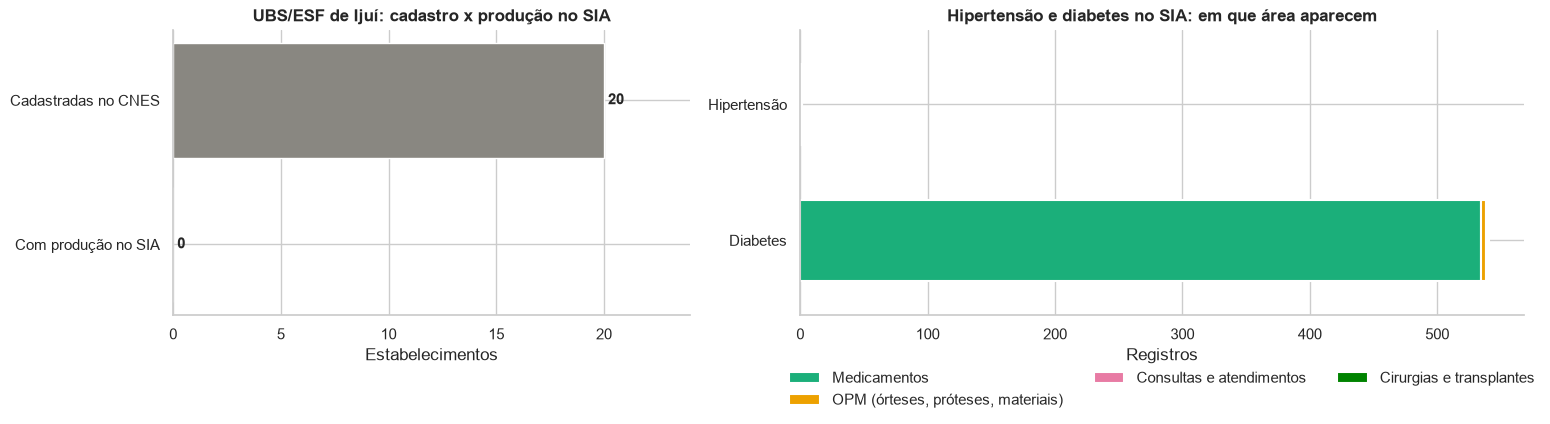

In [34]:
# UBS/ESF cadastradas em Ijuí (cadgerrs) x estabelecimentos com produção no SIA (VIEW).
ubs = ubs_cadastradas.copy()
ubs["Estabelecimento"] = ubs["Estabelecimento"].astype(str).str.strip()
registros_por_estab = tabela["Estabelecimento"].value_counts()
ubs["Registros no SIA"] = ubs["Estabelecimento"].map(registros_por_estab).fillna(0).astype(int)
print(f"UBS/ESF cadastradas em Ijuí: {len(ubs)} | com produção no SIA: {(ubs['Registros no SIA'] > 0).sum()}")
display(ubs)

# Produção com característica de atenção básica dentro do SIA (por tipo de unidade, procedimento ou ocupação).
basica = tabela[
    tabela["TipoUnidade"].isin(["01", "02", "71"])
    | proc_n.str.contains(r"ATENCAO BASICA|ATENCAO PRIMARIA")
    | ocup_n.str.contains(r"SAUDE DA FAMILIA|AGENTE COMUNITARIO")
]
print(f"Registros do SIA com característica de atenção básica: {br_num(len(basica))} "
      f"({br_pct(len(basica) / len(tabela) * 100, 2)} do total)")
if not basica.empty:
    print("Onde estão esses registros (nenhum é de UBS):")
    display(resumo_producao(basica, ["Estabelecimento", "TipoEstabelecimento"])
            .sort_values("Registros", ascending=False).head(8))

# Acompanhamento de doenças crônicas: onde hipertensos e diabéticos são atendidos no SIA?
cid3_total = tabela["CID"].str[:3]
tabela["GrupoCronico"] = np.select(
    [cid3_total.between("I10", "I15"), cid3_total.between("E10", "E14")],
    ["Hipertensão", "Diabetes"], default="")
cronicos_sia = tabela[tabela["GrupoCronico"] != ""]
cronico_estab = pd.crosstab([cronicos_sia["TipoEstabelecimento"], cronicos_sia["Area"]], cronicos_sia["GrupoCronico"])
print("Registros com CID de hipertensão ou diabetes, por tipo de estabelecimento e área:")
display(cronico_estab)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
situacao = pd.Series({"Cadastradas no CNES": len(ubs), "Com produção no SIA": int((ubs["Registros no SIA"] > 0).sum())})
axes[0].barh(situacao.index[::-1], situacao.values[::-1], color=[COR_SERIE, COR_NEUTRA])
for i, v in enumerate(situacao.values[::-1]):
    axes[0].text(v, i, f" {v}", va="center", fontsize=11, fontweight="bold")
axes[0].set_title("UBS/ESF de Ijuí: cadastro x produção no SIA")
axes[0].set_xlabel("Estabelecimentos")
axes[0].set_xlim(0, max(situacao.max() * 1.2, 1))

grupo_area = cronicos_sia.groupby(["GrupoCronico", "Area"]).size().unstack(fill_value=0)
if not grupo_area.empty:
    # No máximo 5 áreas com cor própria; as demais são agrupadas em "Outras áreas" (cinza).
    principais = grupo_area.sum().nlargest(5).index
    outras = grupo_area.drop(columns=principais).sum(axis=1)
    grupo_area = grupo_area[principais]
    if outras.sum() > 0:
        grupo_area["Outras áreas"] = outras
    cores = CORES_CATEGORIAS[2:2 + len(principais)] + ([COR_NEUTRA] if "Outras áreas" in grupo_area else [])
    grupo_area.plot(kind="barh", stacked=True, ax=axes[1], color=cores,
                    width=0.6, edgecolor="white", linewidth=1.5)
    axes[1].legend(title=None, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
    formatar_eixo(axes[1], "x")
axes[1].set_title("Hipertensão e diabetes no SIA: em que área aparecem")
axes[1].set_xlabel("Registros")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Interpretação:** Ijuí tem **20 UBS/ESF cadastradas no CNES** (Unidades Básicas, equipes de Estratégia Saúde da Família e o Posto Central da SMS), e **nenhuma** apresenta produção no SIASUS em jul/2026. Isso não é falha de dado: as consultas, visitas e o acompanhamento de doenças crônicas nas UBS/ESF são registrados no **SISAB (e-SUS APS)**, outro sistema do Ministério da Saúde. A mesma razão explica o que aparece de doenças crônicas no SIA:

- **Hipertensão:** praticamente ausente (cerca de 1 registro).
- **Diabetes:** aparece quase só como **dispensação de insulinas e medicamentos** pela 17ª CRS, e não como acompanhamento.

**Recomendação à Secretaria:** para avaliar a atenção básica e o cuidado de hipertensos e diabéticos, é preciso **complementar o SIA com o SISAB**, que tem relatórios públicos de produção por município e os indicadores de financiamento da APS. O SIA mostra a **porta especializada**; a atenção básica é a **porta de entrada**, e está em outro sistema.

---
## 9. Conclusões e limitações

### Painel-resumo de indicadores

In [35]:
indicadores = pd.Series({
    "Período analisado (movimentação)": ", ".join(mensal["MAExt"]),
    "Registros (VIEW = pars, validado)": br_num(len(tabela)),
    "Linhas idênticas mantidas (atendimentos legítimos)": br_num(duplicados.sum()),
    "Procedimentos produzidos": br_num(tabela["pa_qtdpro"].sum()),
    "Procedimentos aprovados": br_num(tabela["pa_qtdapr"].sum()),
    "Taxa de aprovação (quantidade)": br_pct(tabela["pa_qtdapr"].sum() / tabela["pa_qtdpro"].sum() * 100),
    "Valor produzido": br_moeda(valor_prod),
    "Valor aprovado": br_moeda(valor_aprov),
    "Taxa de aprovação (valor)": br_pct(valor_aprov / valor_prod * 100),
    "Gasto médio por procedimento aprovado": br_moeda(valor_aprov / tabela["pa_qtdapr"].sum()),
    "Maior produtor (qtd aprovada)": ranking.iloc[0]["Estabelecimento"],
    "Registros de não residentes em Ijuí": br_pct(participacao.loc["Outros municípios", "Registros"])
        if "Outros municípios" in participacao.index else "0%",
    "Registros com CID válido": br_pct(len(com_cid) / len(tabela) * 100),
    "Valor aprovado em oncologia": br_moeda(onco["pa_valapr"].sum()),
    "Registros de saúde mental": br_num(len(mental)),
})
display(indicadores.to_frame("Valor"))

,Valor
Período analisado (movimentação),Jul-2026
"Registros (VIEW = pars, validado)",68.827
Linhas idênticas mantidas (atendimentos legítimos),26.874
Procedimentos produzidos,461.059
Procedimentos aprovados,364.679
Taxa de aprovação (quantidade),"79,1%"
Valor produzido,"R$ 6.272.060,94"
Valor aprovado,"R$ 6.158.024,69"
Taxa de aprovação (valor),"98,2%"
Gasto médio por procedimento aprovado,"R$ 16,89"


### Principais achados para a Secretaria Municipal de Saúde

Os números entre parênteses referem-se a jul/2026.

0. **Qualidade da base:** a validação da carga encontrou uma duplicação **criada no banco** (14 CIDs em minúsculo na `s_cid`) que inflava o valor aprovado de Ijuí em cerca de R$ 682 mil. A correção no banco e a validação automática (Seção 1.0) garantem que os indicadores batem com o arquivo oficial.
1. **Volume × valor:** a 17ª CRS lidera em quantidade, com 100% medicamentos (cerca de 57% da quantidade aprovada), enquanto o **HCI** concentra mais da metade do **valor aprovado**. A gestão deve olhar **volume e valor separadamente**.
2. **Aprovado × produzido:** foram aprovados cerca de 79% da quantidade, mas cerca de 98% do valor, então as glosas se concentram em procedimentos de baixo custo. Pontos de atenção para o faturamento:
   - o **Hospital Bom Pastor**, com 53% da quantidade aprovada, mas valor aprovado acima do produzido;
   - o **CAPS do Bosque**, com 65% da quantidade aprovada.
3. **Referência macrorregional:** cerca de 64% do valor aprovado atende **moradores de outros municípios**. Desse total:
   - cerca de 30 pontos percentuais vêm da própria Região 13;
   - cerca de **34%** do valor (R$ 2,1 milhões) vem de **outras regiões de saúde**: restante da Macro Missioneira e Macro Norte.

   A oncologia é o serviço de maior alcance, com mais da metade do valor vindo de fora da Região 13. Isso reforça a necessidade de **pactuação regional** (PPI).
4. **Oncologia:** cerca de R$ 2,0 milhões, um terço do valor do município, com cerca de 1.990 pacientes em quimioterapia e 144 em radioterapia no mês, 80% de fora de Ijuí. A aprovação é quase total, então o risco está em **capacidade e financiamento**, e não em glosa.
5. **Saúde mental:** a rede CAPS sustenta a maior parte dos atendimentos, com modelo multiprofissional.
6. **Atenção básica e doenças crônicas:** nenhuma das UBS/ESF cadastradas tem produção no SIA. Hipertensão quase não aparece, e diabetes aparece só como dispensação de insulinas. O monitoramento dessas condições depende do **SISAB**.

### Limitações e como foram tratadas

| Limitação | Tratamento |
|---|---|
| Duplicação criada na carga (`s_cid`) | Corrigida no banco (`05-corrige-s_cid.sql`) e validada a cada execução (Seção 1.0) |
| Linhas idênticas no PARS | Mantidas: o arquivo público não tem data nem identificação do paciente, então são atendimentos legítimos (Seção 2.2) |
| Sexo, idade e CID "inválidos" | Explicados pelo instrumento de registro (BPA consolidado não identifica o paciente) e tratados como "Não informado" |
| Registros ≠ pacientes | Sem solução no arquivo público (LGPD). Na oncologia, as APACs distintas aproximam o nº de pacientes |
| Tipo de estabelecimento | Classificação oficial do CNES (`pa_tpups`), sem depender do nome |
| Área do procedimento | Hierarquia oficial SIGTAP (`pa_proc_id`). Só saúde mental usa a ocupação (CBO) e o tipo CAPS |
| Atenção básica ausente | Limitação da fonte: a APS é registrada no SISAB. Evidenciada pelo cruzamento com o CNES (Seção 8.3) |
| **Um único mês** (PARS2607) | **Pendente:** carregar mais meses (`PARS2604a/b` a `PARS2606a/b`) para analisar tendência, picos e quedas. O notebook se ajusta sozinho |
| Movimentação × competência | A VIEW traz `Competencia` (`pa_cmp`). Em jul/2026, só cerca de 0,6% do valor foi apresentado com atraso |
| Microrregião IBGE indisponível | Na base territorial de jun/2026, 497 dos 498 municípios do RS apontam para um código inexistente em `tb_micibge`. Usamos a **Macrorregião de Saúde** (Seção 6.2) |
| Município de origem inválido | O código `999999` ("Invalido", BPA consolidado) é tratado como origem **não informada**, e não como "outro município" |

## Comandos utilizados

| Comando | Aplicação no notebook |
|---|---|
| `cursor.execute()` + `fetchall()` | Executar os scripts da DIMTEMPO e da VIEW e carregar os dados |
| `information_schema` | Verificar se a tabela/coluna já existe antes de executar os scripts |
| `pd.to_numeric()`, `pd.to_datetime()` | Preparar variáveis numéricas e datas |
| `.describe()`, `.median()`, `.value_counts()` | Estatística descritiva e frequências |
| `.isna()`, `.fillna()`, `.replace()` | Tratar ausentes ("Não informado") |
| `COUNT(*) - COUNT(DISTINCT chave)` | Validar a carga: chaves repetidas que multiplicariam linhas nos `JOIN`s |
| `.duplicated()` | Identificar linhas idênticas e medir o impacto de removê-las |
| `.merge(validate="many_to_one")` | Relacionar produção × DIMTEMPO |
| `.str[:4]` + `np.select()` | Classificar áreas pela hierarquia SIGTAP e grupos de CID |
| `.map(dicionário)` | Traduzir códigos (tipo de unidade CNES, instrumento de registro) |
| `.str.contains()` | Saúde mental pela ocupação (CBO) |
| `.nunique()` | APACs distintas (≈ pacientes em oncologia) |
| `pd.crosstab(..., values=, aggfunc="sum", normalize="index")` | Alcance regional de cada área (% do valor por origem) |
| `.encode("latin1").decode("utf-8")` | Corrigir nomes com codificação trocada |
| `pd.cut()` | Faixas etárias |
| `.groupby().agg()`, `pd.crosstab()`, `.pivot_table()` | Agregações e tabelas cruzadas |
| `.pct_change()` | Variação temporal |
| `plt.subplots()`, `.barh()`, `.plot()`, `sns.heatmap()` | Visualizações |